## 🤖 Complete Plant Simulation Specification: Discrete-Time Open-Loop Asymmetric 4-Omni Robot Model

This cell specifies the comprehensive mathematical framework for the 4-wheel omni-directional mobile robot simulation. The architecture accounts for **asymmetric wheel layouts**, **dynamic multi-axis weight transfer (pitch and roll)**, **disturbanced from real world system vibration and noise** and **non-linear stick-slip traction transitions** derived explicitly for digital execution at a fixed sampling interval $\Delta T$ (or $T_s$).

---
<details>
<summary><b> Open this for the full specification of the simulation equations</b></summary>


### 1. Parameters & Variable Definitions

#### 🛠️ Hardware & Structural Parameters
* $M_r$: Total mass of the robot chassis (kg)
* $J_{zz}$: Rotational mass moment of inertia of the robot around its vertical Z-axis (kg·m²)
* $J_w$: Rotational mass moment of inertia of an individual wheel/rotor assembly (kg·m²)
* $R_b$: Geometric radius of the robot base circle from the Center of Mass (meters)
* $r$: Operating radius of the omni-wheel tires (meters)
* $\alpha_f$: Mounting angle of the front wheels relative to the local $+x_r$-axis (right), measured counter-clockwise (rad)
* $\alpha_b$: Mounting angle of the rear wheels relative to the local $+x_r$-axis (right), measured clockwise (rad)
* $h$: Height of the robot Center of Mass (CoM) above the ground plane (meters)
* $y_{cg}$: Position of the Center of Mass forward of the base centre (meters)
* $R, L_m$: Armature resistance ($\Omega$) and inductance (H) of individual DC motors
* $K_t, K_b$: Electromechanical torque (Nm/A) and back-EMF (V/(rad/s)) constants
* $V_{bus}, \eta$: Battery (bus) voltage (V) and the driver's modulation limit (largest applied voltage as a fraction of $V_{bus}$)
* $I_{max}$: Driver current command limit per motor (A)
* $\omega_c, f_{pwm}, \kappa, \gamma, \varepsilon_V$: Driver current-loop bandwidth (rad/s), loop rate (Hz), current-estimate filter gain and integrator decay per period while the voltage is limited, and the width of the smoothed anti-windup switch (V)
* $C_{rr}$: Floor-tire rolling resistance coefficient
* $\mu_s, \mu_k$: Static and kinetic coefficients of friction between tire rollers and floor
* $\alpha_d$: Stribeck decay rate of the friction coefficient from $\mu_s$ to $\mu_k$ with slip speed (s/m)
* $\delta, \zeta, v_\sigma, \sigma_2, v_c$: LuGre bristle deflection at the static limit (m), bristle damping ratio, slip speed over which the bristle damping fades out (m/s), viscous friction coefficient (N·s/m), and creep slip (m/s)
* $\varepsilon$: Wheel speed scale of the smoothed rolling resistance (rad/s)

---

### 2. Signal Tracker Definitions

At each sample time step $k$, the discrete simulation cycle processes the following variables:

#### System Inputs
* $\mathbf{I}_{cmd,k} = [i_{cmd,1,k}, i_{cmd,2,k}, i_{cmd,3,k}, i_{cmd,4,k}]^\top$: Motor current commands sent to each wheel's driver (Amperes), or
* $\mathbf{V}_{k} = [V_{1,k}, V_{2,k}, V_{3,k}, V_{4,k}]^\top$: Motor voltage commands applied straight to the motor terminals, bypassing the driver (Volts), as in the original model and its tests.

#### Tracked Memory Integration States
* $\mathbf{I}_k = [i_{1,k}, i_{2,k}, i_{3,k}, i_{4,k}]^\top$: Motor armature current states (Amperes).
* $\hat{\mathbf{I}}_k = [\hat{i}_{1,k}, \dots, \hat{i}_{4,k}]^\top$, $\mathbf{X}_{I,k} = [x_{I,1,k}, \dots, x_{I,4,k}]^\top$: Driver current estimates (Amperes) and current-loop integrators (Volts).
* $\mathbf{\Omega}_k = [\omega_{1,k}, \omega_{2,k}, \omega_{3,k}, \omega_{4,k}]^\top$: Mechanical wheel angular velocity states (rad/s).
* $\mathbf{Z}_k = [z_{1,k}, z_{2,k}, z_{3,k}, z_{4,k}]^\top$: LuGre bristle load states, as a fraction of the presliding deflection $\delta$ (dimensionless).
* $\mathbf{\dot{X}}_{r,k} = [\dot{x}_{r,k}, \dot{y}_{r,k}, \dot{\theta}_{k}]^\top$: Local robot coordinate chassis velocities, $x_r$ right and $y_r$ forward (m/s, m/s, rad/s). Derived from the global velocities, for $\mathbf{H}$.
* $\mathbf{\ddot{X}}_{r,k-1} = [a_{x,r,k-1}, a_{y,r,k-1}, \alpha_{r,k-1}]^\top$: Lagged chassis accelerations (one step of lag) that set the normal force weight transfer allocations (m/s², m/s², rad/s²).
* $\mathbf{\dot{X}}_{g,k} = [\dot{x}_{g,k}, \dot{y}_{g,k}, \dot{\theta}_{g,k}]^\top$: Global room frame chassis velocities (m/s, m/s, rad/s). The integrated velocity state: Newton's law holds in this fixed frame.
* $\mathbf{X}_{g,k} = [x_k, y_k, \theta_k]^\top$: Absolute global room frame navigation positions (meters, meters, radians).

#### Plant Observation and Feedback Outputs (Algebraic Trackers)
* $\mathbf{V}_{a,k} = [V_{a,1,k}, \dots, V_{a,4,k}]^\top$, $I_{bus,k}$: Voltage applied by each driver and battery current, averaged over step $k$ (Volts, Amperes).
* $\mathbf{T}_{m,k} = [T_{m,1,k}, T_{m,2,k}, T_{m,3,k}, T_{m,4,k}]^\top$: Instantaneous electromagnetic motor drive torque vector (Nm).
* $\mathbf{F}_{n,k} = [F_{n,1,k}, F_{n,2,k}, F_{n,3,k}, F_{n,4,k}]^\top$: Dynamic normal loading force per wheel including pitch/roll transfer (Newtons).
* $\mathbf{T}_{roll,k} = [T_{roll,1,k}, T_{roll,2,k}, T_{roll,3,k}, T_{roll,4,k}]^\top$: Parasitic floor rolling resistance torques opposing wheel rotation (Nm).
* $\mathbf{F}_k = [F_{1,k}, F_{2,k}, F_{3,k}, F_{4,k}]^\top$: Active non-linear tractive forces transmitted from the floor patch to the robot frame (Newtons).
* $\mathbf{S}_k = [s_{1,k}, s_{2,k}, s_{3,k}, s_{4,k}]^\top$: Boolean wheel traction indicator status vector, where $s_{i,k} = 0$ for Pure Rolling (Sticking) and $s_{i,k} = 1$ for Skidding/Spinout (Slipping).
* $\mathbf{T}_{load, k} = [T_{load,1,k}, T_{load,2,k}, T_{load,3,k}, T_{load,4,k}]^\top$: Mechanical load torque vectors experienced by each motor armature (Nm).
* $\mathbf{X}_{g,k+1} = [x_{k+1}, y_{k+1}, \theta_{k+1}]^\top$: Updated absolute global navigation coordinate profile shifted into the next step.

---

### 3. Kinematic Kinematics Mapping Matrix ($\mathbf{H}$)

The transformation matrix $\mathbf{H}$ projects the rigid chassis velocities into ideal linear speeds parallel to the driving direction of the wheel contact patches. Given the front/back asymmetry ($\alpha_f \neq \alpha_b$), it is defined as:

The chassis motion is measured about the centre of mass, which sits $y_{cg}$ forward of the base centre (10.2 mm for the built robot, from CAD; Dana's original model took $y_{cg} = 0$). $J_{zz}$ is the yaw inertia about the centre of mass. Each wheel's yaw lever about it is $R_b - y_{cg} \sin\beta_i$:

$$\mathbf{H} = \begin{bmatrix} -\sin(\alpha_f) & \cos(\alpha_f) & R_b - y_{cg}\sin(\alpha_f) \\  -\sin(\alpha_f) & -\cos(\alpha_f) & R_b - y_{cg}\sin(\alpha_f) \\  \sin(\alpha_b) & -\cos(\alpha_b) & R_b + y_{cg}\sin(\alpha_b) \\  \sin(\alpha_b) & \cos(\alpha_b) & R_b + y_{cg}\sin(\alpha_b) \end{bmatrix}$$

$$\mathbf{V}_{wheel, k} = \mathbf{H} \mathbf{\dot{X}}_{r,k}$$


$$
\begin{bmatrix} v_1 \\ v_2 \\ v_3 \\ v_4 \end{bmatrix}_k = H \begin{bmatrix} \dot{x}_r \\ \dot{y}_r \\ \dot{\theta} \end{bmatrix}_k
$$


---

### 4. Sequential Step Execution Flow

1. **Read System Inputs and States**: Load the current or voltage command vector and the historical state markers from step k, and draw the disturbances for the step.
2. **Compute Electrical Motor Torque**: Evaluate the motor drivers' current loops and the motor circuits, and the gross torque produced by the motor armatures.
3. **Calculate Dynamic Normal Forces**: Apply structural wheelbase configurations and the lagged accelerations to check real-time load distribution.
4. **Contact Mechanics Constraints**: Compute the smoothed rolling resistance and the LuGre floor forces from the bristle states.
5. **Chassis Rigid Body Acceleration**: Extract local accelerations through the inverse mass and transposed kinematics matrices.
6. **Velocity Integration and Frame Rotation**: Rotate the local accelerations into the global room frame, where the chassis velocities are integrated, and derive the local velocities from them.
7. **Global Position Advancement**: Integrate every rate of steps 2–6 together over the step with the implicit solver (Radau).
8. **Back-Projection & Feedback Loop Closure**: Store the integrated states, and isolate the output load torque, applied voltage and battery current values.


---
### 5. Subsystem Equations (Integrated Implicitly Each Step)

Each step below gives the **rate of change** of its states. All of them are integrated together over every step $dt$ by the implicit adaptive solver Radau (Step 5.7), with the commands and the disturbance draws held over the step.

#### Step 5.1: Discrete Electrical Motor Current System (Simovr Current Loop)
The input to each motor is a current command $i_{cmd,i,k}$. As on the robot, the Simovr motor driver (Tinymovr firmware) turns the error between the command and its measured current into the voltage it applies, and the motor's electrical equation then sets the actual current. The firmware runs this loop every PWM period $T_{pwm} = 1 / f_{pwm}$ (50 µs), far faster than the loop's bandwidth, so it is written here as a continuous loop.

With a voltage command instead, the driver is bypassed and its states hold: the commanded voltage goes straight to the motor terminals, $V_i = \text{clip}\left(V_{i,k}, \ -\eta V_{bus}, \ \eta V_{bus}\right)$, and only the motor's electrical equation below applies.

The driver clamps each command to its current limit:
$$
i_{set,i} = \text{clip}\left(i_{cmd,i,k}, \ -I_{max}, \ I_{max}\right)
$$

It filters its current measurement (the firmware's $\kappa$ per period, as a rate):
$$
\frac{d\hat{i}_i}{dt} = \lambda_f \cdot \left(i_i - \hat{i}_i\right), \qquad \lambda_f = -\ln(1 - \kappa) \cdot f_{pwm}
$$

and runs a PI controller on the error, with gains set from the current-loop bandwidth $\omega_c$:
$$
K_p = \omega_c \cdot L_m, \qquad K_i = \omega_c \cdot R
$$
$$
e_i = i_{set,i} - \hat{i}_i
$$
$$
V_i = \text{clip}\left(K_p \cdot e_i + x_{I,i}, \ -\eta V_{bus}, \ \eta V_{bus}\right)
$$
$$
\frac{dx_{I,i}}{dt} = K_i \cdot e_i - s_i \cdot \lambda_\gamma \cdot x_{I,i}, \qquad \lambda_\gamma = -\ln(\gamma) \cdot f_{pwm}
$$

While the voltage is limited, the integrator decays (the firmware's $\gamma$ per period, as a rate). The switch $s_i$ goes from 0 to 1 as the unlimited voltage passes the limit, smoothed over a width $\varepsilon_V$ so the solver sees no jump:
$$
s_i = \frac{1}{2}\left(1 + \tanh\left(\frac{|K_p e_i + x_{I,i}| - \eta V_{bus}}{\varepsilon_V}\right)\right)
$$

The continuous electrical differential equation for a motor is $V(t) = R \cdot i(t) + L_m \frac{di(t)}{dt} + K_b \cdot \omega(t)$. Isolating the current derivative yields:
$$
\frac{di_i}{dt} = \frac{1}{L_m}\left(V_i - R \cdot i_i - K_b \cdot \omega_i\right)
$$

The instantaneous gross electromagnetic torque vector produced by the armatures maps directly from the current:

$$
\mathbf{T}_{m} = \begin{bmatrix} T_{m,1} \\ T_{m,2} \\ T_{m,3} \\ T_{m,4} \end{bmatrix} = K_t \begin{bmatrix} i_{1} \\ i_{2} \\ i_{3} \\ i_{4} \end{bmatrix}
$$

The applied voltage and the battery current are reported as averages over the step:
$$
V_{a,i,k} = \frac{1}{dt} \int_{t_k}^{t_{k+1}} V_i \, dt
$$
$$
I_{bus,k} = \frac{1}{dt} \int_{t_k}^{t_{k+1}} \frac{\sum_i V_i \cdot i_i}{V_{bus}} \, dt
$$

#### Step 5.2: Dynamic Normal Force Balance
Extract vehicle geometry parameters relative to the Center of Mass:
$$
x_f = R_b\cos(\alpha_f), \quad x_b = R_b\cos(\alpha_b), \quad \Sigma X^2 = x_f^2 + x_b^2
$$
$$
y_f = R_b\sin(\alpha_f), \quad y_b = R_b\sin(\alpha_b), \quad L = y_f + y_b
$$

The front and rear axle distances from the centre of mass:
$$
y_{f,cg} = y_f - y_{cg}, \quad y_{b,cg} = y_b + y_{cg}
$$

To prevent algebraic system loops, the load transfer uses lagged accelerations $\tilde{a}_x, \tilde{a}_y$ that follow the chassis accelerations of Step 5.4 with a lag of one step ($\tau = dt$), the continuous counterpart of using the previous step's acceleration:
$$
\frac{d\tilde{a}_x}{dt} = \frac{a_{x,r} - \tilde{a}_x}{\tau}, \qquad \frac{d\tilde{a}_y}{dt} = \frac{a_{y,r} - \tilde{a}_y}{\tau}
$$

Calculate the individual tire normal forces ($F_{n,i}$):
$$
F_{n,1} = \frac{M_r g y_{b,cg}}{2L} - \frac{M_r \tilde{a}_y h}{2L} - \left( \frac{x_f}{\Sigma X^2} \right) \frac{M_r \tilde{a}_x h y_{b,cg}}{L}
$$
$$
F_{n,2} = \frac{M_r g y_{b,cg}}{2L} - \frac{M_r \tilde{a}_y h}{2L} + \left( \frac{x_f}{\Sigma X^2} \right) \frac{M_r \tilde{a}_x h y_{b,cg}}{L}
$$
$$
F_{n,3} = \frac{M_r g y_{f,cg}}{2L} + \frac{M_r \tilde{a}_y h}{2L} + \left( \frac{x_b}{\Sigma X^2} \right) \frac{M_r \tilde{a}_x h y_{f,cg}}{L}
$$
$$
F_{n,4} = \frac{M_r g y_{f,cg}}{2L} + \frac{M_r \tilde{a}_y h}{2L} - \left( \frac{x_b}{\Sigma X^2} \right) \frac{M_r \tilde{a}_x h y_{f,cg}}{L}
$$

#### Step 5.3: Non-Linear Contact Patch Friction Model (LuGre)
For each wheel $i$, calculate internal rolling drag (smoothed through zero wheel speed) and the contact-point slip speed along the drive direction:
$$
T_{roll, i} = C_{rr} \cdot F_{n,i} \cdot r \cdot \tanh\left(\frac{\omega_{i}}{\varepsilon}\right)
$$
$$
v_{s,i} = (H \mathbf{\dot{X}}_{r})_i - r \cdot \omega_{i}
$$

The friction coefficient follows the Stribeck curve, from $\mu_s$ at zero slip down to $\mu_k$ in sliding:
$$
\mu_{d,i} = \mu_k + (\mu_s - \mu_k) \cdot e^{-\alpha_d |v_{s,i}|}
$$

Each wheel carries a bristle load $z_i$ (LuGre, Canudas de Wit et al. 1995), as a fraction of the bristle deflection $\delta$ at the static limit $\mu_s \cdot F_{n,i}$:
$$
\frac{dz_i}{dt} = \frac{1}{\delta} \left( v_{s,i} - \frac{\mu_s}{\mu_{d,i}} \sqrt{v_{s,i}^2 + v_c^2} \cdot z_i \right)
$$
$$
\sigma_{1,i} = 2 \zeta \sqrt{\frac{\mu_s F_{n,i}}{\delta} \cdot \frac{J_w}{r^2}} \cdot e^{-(v_{s,i} / v_\sigma)^2}
$$

The floor force on the robot along each wheel's drive direction is:
$$
F_{i} = -\left( \mu_s F_{n,i} \cdot z_i + \sigma_{1,i} \, \delta \cdot \frac{dz_i}{dt} + \sigma_2 \cdot v_{s,i} \right)
$$

There is no stick/slip switch. While a wheel grips, its slip stays near zero and the bristles hold the load, up to $\mu_s F_{n,i}$. In steady sliding $\frac{dz_i}{dt} = 0$, so $z_i = \mu_{d,i} / \mu_s$ and $F_i = -\text{sign}(v_{s,i}) \cdot \mu_{d,i} \cdot F_{n,i}$. The slip flag is a diagnostic only:
$$
s_{i,k} = \begin{cases} 1 & \text{if } |v_{s,i,k+1}| > v_{band} \quad \text{(Slipping)} \\ 0 & \text{otherwise} \quad \text{(Gripping)} \end{cases}
$$

#### Step 5.4: Chassis Frame Mechanical Kinetics
Calculate multi-axis robot-frame accelerations by combining the horizontal forces through the transposed kinematics configuration matrix $H^\top$:
$$
\begin{bmatrix} a_{x,r} \\ a_{y,r} \\ \alpha_{r} \end{bmatrix} = \begin{bmatrix} \frac{1}{M_r} & 0 & 0 \\ 0 & \frac{1}{M_r} & 0 \\ 0 & 0 & \frac{1}{J_{zz}} \end{bmatrix} H^\top \begin{bmatrix} F_{1} \\ F_{2} \\ F_{3} \\ F_{4} \end{bmatrix}
$$

Newton's law holds in the stationary global room frame, so the chassis velocities are integrated there. The wheels are fixed to the chassis, so their forces act along body directions; transform the local accelerations into global room accelerations via the heading angle $\theta$:
$$
\frac{d\dot{x}_g}{dt} = a_{x,r}\cos(\theta) - a_{y,r}\sin(\theta)
$$
$$
\frac{d\dot{y}_g}{dt} = a_{x,r}\sin(\theta) + a_{y,r}\cos(\theta)
$$
$$
\frac{d\dot{\theta}}{dt} = \alpha_r
$$

#### Step 5.5: Frame Transfer Pipeline
The global velocities are the rates of the absolute spatial positions:
$$
\frac{dx}{dt} = \dot{x}_{g}, \qquad \frac{dy}{dt} = \dot{y}_{g}, \qquad \frac{d\theta}{dt} = \dot{\theta}
$$

Transform the global velocities into local robot velocities via the heading angle $\theta$; these are what $\mathbf{H}$ projects onto the wheels in Step 5.6:
$$
\dot{x}_{r} = \dot{x}_{g}\cos(\theta) + \dot{y}_{g}\sin(\theta)
$$
$$
\dot{y}_{r} = -\dot{x}_{g}\sin(\theta) + \dot{y}_{g}\cos(\theta)
$$

The local velocities are not integrated themselves. The local axes turn with the robot, so integrating $\frac{d\dot{x}_r}{dt} = a_{x,r}$ directly (as the original model did) leaves out the change of the axes, the term $-\boldsymbol\omega \times \mathbf{\dot{X}}_r$, and a robot that moves while it turns follows a wrong, curved path.

#### Step 5.6: Mechanical Re-coupling and Dynamic Load Torque Calculations
To map the floor interaction directly back to the motor mechanical velocity derivatives, project the chassis speeds onto the wheels using the kinematic configuration matrix:
$$
\begin{bmatrix} v_{1} \\ v_{2} \\ v_{3} \\ v_{4} \end{bmatrix} = H \begin{bmatrix} \dot{x}_{r} \\ \dot{y}_{r} \\ \dot{\theta} \end{bmatrix}
$$

Every wheel follows the same torque balance; there is no sticking/slipping split. The floor force acts on the rim through $r$:
$$
J_w \frac{d\omega_i}{dt} = T_{m,i} - T_{roll,i} - r \cdot F_i
$$

The load torque on each motor is reported as an average over the step:
$$
T_{load, i,k} = \frac{1}{dt} \int_{t_k}^{t_{k+1}} \left( F_{i} \cdot r + T_{roll,i} \right) dt
$$

A gripping wheel rolls with the chassis ($r \omega_i \approx v_i$, within the creep slip), and a sliding wheel spins independently against its inertia $J_w$.

*The wheel angular speeds $\mathbf{\omega}$ act directly as the $K_b \cdot \omega$ Back-EMF source in the electrical equation of Step 5.1, completing the bilateral electromechanical connection loop.*

#### Step 5.7: Implicit Integration over the Step
The state vector collects every state of Steps 5.1–5.6:
$$
\mathbf{x} = \left[ \mathbf{I}, \ \hat{\mathbf{I}}, \ \mathbf{X}_I, \ \boldsymbol{\omega}, \ \mathbf{Z}, \ \mathbf{\dot{X}}_g, \ \mathbf{X}_g, \ \tilde{a}_x, \ \tilde{a}_y \right]
$$

and the steps above give its rate of change, $\frac{d\mathbf{x}}{dt} = f(\mathbf{x}, \mathbf{I}_{cmd,k})$ (or $\mathbf{V}_k$). Each step, the implicit adaptive solver Radau (SciPy `solve_ivp`, relative tolerance `rtol`) integrates it from $t_k$ to $t_{k+1}$ with the commands and the disturbance draws held. The solver chooses its own internal step sizes: small while a wheel breaks loose or a current changes quickly, large otherwise. They are recorded in `last_steps`, so they can be tracked over time. It is implicit, so the stiff parts (the motor current, the driver and the LuGre bristles) cannot make it unstable.

#### 7. Environmental Disturbances: Structural Vibrational Noise and Inconsistent Friction

To transition this plant from an ideal simulation to an authentic physical environment, we inject two forms of non-deterministic disturbances ($\mathbf{W}_k$) into the state equations at each time step $k$.

$$\begin{array}{rcccl}
[\text{Ideal Normal Force } F_{n, \text{ideal}}] & \longrightarrow & + \text{ Structural Vibration Noise } w_{F} & \longrightarrow & [\text{Perturbed } F_{n,i,k}] \\
[\text{Ideal Friction Coeff } \mu_{\text{nominal}}] & \longrightarrow & + \text{ Spatial Friction Variance } w_{\mu} & \longrightarrow & [\text{Perturbed } \mu_{s,i,k} \ / \ \mu_{k,i,k}]
\end{array}$$



##### Phase 1: High-Frequency Structural Vibrations
Chassis vibrations from gear mesh, floor roughness, and structural flexing cause rapid, high-frequency oscillations in the normal forces ($F_{n,i,k}$). We model this as a zero-mean Gaussian white noise vector added to each wheel's computed normal force:

$$F_{n,i,k,\text{perturbed}} = \max\left(0, \ F_{n,i,k,\text{ideal}} + w_{F,i,k}\right)$$

Where $w_{F,i,k} \sim \mathcal{N}(0, \sigma_V^2)$, and $\sigma_V$ represents the standard deviation of the mechanical vibration amplitude (in Newtons). 
* *Note: The $\max(0, \dots)$ ceiling constraint ensures that severe vibrational spikes cannot physically pull the wheel "through" the floor or simulate a negative normal force.*

##### Phase 2: Inconsistent Spatial Friction Coefficients
Floor conditions like dust patches, scuff marks, or changing floor tile seams cause the local friction constants ($\mu_s, \mu_k$) to vary over time as the robot travels. To model this, we alter the baseline friction coefficients with a bounded random noise profile at each time step:

$$\mu_{s,i,k} = \max\left(0, \ \mu_{s,\text{nominal}} + w_{\mu,i,k}\right)$$
$$\mu_{k,i,k} = \max\left(0, \ \mu_{k,\text{nominal}} + w_{\mu,i,k}\right)$$

Where $w_{\mu,i,k} \sim \mathcal{N}(0, \sigma_{\mu}^2)$, and $\sigma_{\mu}$ governs the inconsistency or roughness of the floor terrain (typically set between `0.02` and `0.08` for realistic surfaces). 

#### Phase 3: Loop Integration Changes
These perturbed values are injected directly into **Step 5.3 (Non-Linear Friction Model)** through the static limit, the Stribeck curve and the rolling drag:

$$F_{static, i, k} = \mu_{s,i,k} \cdot F_{n,i,k,\text{perturbed}}$$
$$\mu_{d,i} = \mu_{k,i,k} + (\mu_{s,i,k} - \mu_{k,i,k}) \cdot e^{-\alpha_d |v_{s,i}|}$$
$$T_{roll, i} = C_{rr} \cdot F_{n,i,k,\text{perturbed}} \cdot r \cdot \tanh\left(\frac{\omega_{i}}{\varepsilon}\right)$$

The perturbed load also sets the bristle stiffness $\mu_{s,i,k} F_{n,i,k,\text{perturbed}} / \delta$, so the floor force of every wheel, gripping or sliding, follows the disturbances.

* **Simulation Insight:** Adding these perturbations will cause your motor currents ($i_k$) and wheel loads ($T_{load}$) to experience micro-spikes. This accurately simulates real-world conditions where a wheel may momentarily break traction due to a vibration spike or a low-friction spot on the floor, allowing you to rigorously test the resilience of outer control loops.

<details>

---
<details>
<summary><b> Open this for simulation flowchart </b></summary>



```text
==================================================
        SIMULATION STATE DATA (STEP K)
==================================================
 [Inputs] -> Current Commands i_cmd_1..4
            (or Voltage Commands V_1..4)
 [Memory] -> Current i_k, Wheel Speeds omega_k
 [Memory] -> LuGre Bristle Loads z_k
 [Memory] -> Global Chassis Speeds & Past Accel
 [Memory] -> Global Coordinates [x, y, theta]_k
==================================================
                        |
                        v
         +------------------------------+
         |   1. ELECTRICAL SUBSYSTEM    |
         | - Driver PI: Error -> Voltage|
         | - Limit to 0.8 x V_bus       |
         | - Calculate Back-EMF         |
         | - Integrate Armature Current |
         | - Output Electromagnetic T   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    2. STRUCTURAL LOADING     |
         | - Compute Asymmetric Static  |
         | - Shift Load via Past Accel  |
         | - Inject Noise (w_F, w_mu)   |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    3. CONTACT INTERFACE      |
         | - Compute Rolling Resistance |
         | - Slip Speed per Wheel       |
         | - LuGre Bristle Floor Force  |
         | - Bristle Load Rates         |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    4. CHASSIS RIGID BODY     |
         | - Compute Local Accel Vector |
         | - Rotate Accel to Global     |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |    5. COORDINATE ROTATION    |
         | - Global Velocity Rates      |
         | - Global Position Rates      |
         | - Local Velocity for H       |
         +------------------------------+
                        |
                        v
         +------------------------------+
         |   6. MECHANICAL RE-COUPLING  |
         | - Project Wheel Speed Targets|
         | - Wheel Speed Rates          |
         | - Calculate Final Load T_load|
         +------------------------------+
                        |
                        v
         +------------------------------+
         |  7. IMPLICIT SOLVE (RADAU)   |
         | - All Rates 1-6 Together     |
         | - Over the Step dt           |
         | - Commands, Noise Held       |
         +------------------------------+
                        |
                        v
==================================================
       SIMULATION OUTPUT TRAJECTORY (K+1)
==================================================
 [Output] -> New Spatial Coordinates [x, y, theta]
 [Output] -> Composite Motor Load Vector T_load
 [Output] -> True Slip Flag Matrix Indicators
==================================================
```

### 📂 Omni Simulation Class Architecture

The `OmniRobotSimulation` class implements a modular physics engine executed at each time step $\Delta T$: the methods below give the rates of change of the states, and `step` integrates them all together over the step with the implicit solver Radau.

*   **`OmniMotorState`**: Data container that preserves and moves the integrated memory states (currents, driver states, wheel speeds, bristle loads, local/global velocities, positions, and lagged accelerations) from step $k$ to $k+1$.
*   **`__init__`**: Handles parameters, extracts asymmetric chassis dimensions, and pre-builds the mass matrix ($\mathbf{M}$) and its inverse ($\mathbf{M}^{-1}$).
*   **`_build_kinematics_matrix`**: Constructs the asymmetric kinematic velocity projection matrix ($H$) based on mounting angles ($\alpha_f, \alpha_b$).
*   **`compute_electrical_subsystem`**: Rates of the Simovr current loop (command clamp, current filter, PI, voltage limit with anti-windup) and the motor circuit, the applied voltages, and the drive torques ($\mathbf{T}_m$). With a voltage command the driver is bypassed and the voltage goes straight to the motor.
*   **`compute_dynamic_normal_forces`**: Evaluates vertical wheel loads ($\mathbf{F}_{n}$) by combining static splits, lagged-acceleration pitch/roll shifts, and vibration noise ($w_F$).
*   **`lugre_contact`**: LuGre bristle model. Returns the floor force along each wheel's drive direction and the bristle load rates for given slip speeds.
*   **`compute_contact_friction_interface`**: Computes the slip speeds, the LuGre floor forces and bristle load rates, and the smoothed rolling resistance.
*   **`advance_chassis_kinetics`**: Computes chassis rigid body acceleration ($\mathbf{M}^{-1}H^\top\mathbf{F}$) and rotates it via $R(\theta)$ into the global room frame, where the chassis velocities are integrated.
*   **`global_to_local`**: The local chassis velocities from the global ones ($R(\theta)^\top$), for $H$.
*   **`rates`**: Combines the methods above into the rate of change of every state, with the commands and disturbance draws held.
*   **`step`**: Master loop execution engine. Draws the disturbances for the step, integrates `rates` over the step with Radau (its internal step sizes are kept in `last_steps`), and outputs step states alongside data logging tracking metrics ($T_{load}$, applied voltage, battery current, slip flags).

In [1]:
import numpy as np
from scipy.integrate import solve_ivp

class OmniMotorState:
    """
    Data container to log and preserve the electromechanical system states
    at any discrete time step k.
    """
    def __init__(self):
        # Memory Integration States (Differential Cores)
        self.I = np.zeros(4)            # Armature currents [i1, i2, i3, i4] (A)
        self.I_est = np.zeros(4)        # Driver current estimates [i_est1..i_est4] (A)
        self.x_I = np.zeros(4)          # Driver current-loop integrators [x1..x4] (V)
        self.omega = np.zeros(4)        # Wheel angular velocities [w1, w2, w3, w4] (rad/s)
        self.z = np.zeros(4)            # LuGre bristle loads [z1, z2, z3, z4] (fraction of the presliding deflection)
        self.v_local = np.zeros(3)      # Local chassis velocities [x_dot (right), y_dot (forward), theta_dot] (m/s, rad/s), from v_global
        self.a_local_past = np.zeros(3) # Lagged chassis accelerations that set the load transfer [a_x, a_y, alpha] (m/s^2, rad/s^2)
        self.v_global = np.zeros(3)     # Global velocities [x_dot_g, y_dot_g, theta_dot_g] (m/s, rad/s): the integrated velocity state
        self.pos_global = np.zeros(3)   # Global coordinates [x, y, theta] (m, rad)

        # Outputs over the previous step
        self.V_applied = np.zeros(4)    # Voltage each driver applied, averaged over the previous step (V)
        self.I_bus = 0.0                # Battery (bus) current, averaged over the previous step (A)

        # Tracked Logical Status Vector
        self.S = np.zeros(4, dtype=bool) # Traction flags (False=Gripping, True=Slipping)


class OmniRobotSimulation:
    """
    Physics engine plant managing an asymmetric 4-Omni wheel robot model
    with dynamic weight transfer and LuGre floor friction.

    Every state (motor currents, driver states, wheel speeds, bristle loads, global chassis velocities, pose and
    the lagged accelerations behind the load transfer) is integrated together over each step dt with an
    implicit adaptive solver (Radau). The commands and the disturbance draws are held over the step.
    The chassis velocity is integrated in the global (room) frame, where Newton's law holds; the local velocity
    that H needs is derived from it.
    """
    # Positions of each state block in the solver vector
    _I, _IE, _XI, _W, _Z = slice(0, 4), slice(4, 8), slice(8, 12), slice(12, 16), slice(16, 20)
    _V, _POS, _AL = slice(20, 23), slice(23, 26), slice(26, 28)   # _V: global chassis velocities
    _QF, _QR, _QV, _QB = slice(28, 32), slice(32, 36), slice(36, 40), slice(40, 41)   # step integrals for averages

    def __init__(self, params: dict,random_seed: int = 42):
        """
        Initializes hardware constants, geometric parameters, and noise variances.
        """
        self.p = params
        self.dt = params['dt']

        # Pre-compute fixed kinematic tracking matrix (H) based on alpha_f and alpha_b
        self.H = self._build_kinematics_matrix()

        # Instantiate a dedicated, isolated random number generator state for this plant
        self.rng = np.random.default_rng(seed=random_seed)

        # --- BUILD THE MASS / INERTIA MATRIX (M) ---
        self.M = np.array([
            [self.p['Mr'], 0.0,           0.0],          # Mass acting on X acceleration
            [0.0,          self.p['Mr'],  0.0],          # Mass acting on Y acceleration
            [0.0,          0.0,           self.p['Jzz']] # Rotational inertia acting on Alpha
        ])

        # Pre-compute the Inverse Mass Matrix (M_inv) for high efficiency in step calls
        self.M_inv = np.linalg.inv(self.M)

        # Structural wheelbase lengths for weight distribution balances
        self.x_f = self.p['Rb'] * np.cos(self.p['alpha_f'])
        self.x_b = self.p['Rb'] * np.cos(self.p['alpha_b'])
        self.y_f = self.p['Rb'] * np.sin(self.p['alpha_f'])
        self.y_b = self.p['Rb'] * np.sin(self.p['alpha_b'])
        self.L = self.y_f + self.y_b
        # Front and rear axle distances from the centre of mass, which sits cog_y forward of the base centre
        self.y_f_cg = self.y_f - self.p['cog_y']
        self.y_b_cg = self.y_b + self.p['cog_y']
        self.sum_X2 = (self.x_f**2) + (self.x_b**2)

        # Rim inertia the LuGre bristles act against (J_w / r^2)
        self.m_rim = self.p['Jw'] / self.p['r']**2

        # Simovr current loop: gains set from its bandwidth as the firmware does (controller_update_I_gains),
        # and its per-period filter and anti-windup decay written as rates (they act every 1/pwm_freq)
        self.Kp_I = self.p['I_bw'] * self.p['Lm']
        self.Ki_I = self.p['I_bw'] * self.p['R']
        self.V_max = self.p['pwm_limit'] * self.p['V_bus']
        self.filter_rate = -np.log(1.0 - self.p['current_filter_gain']) * self.p['pwm_freq']
        self.decay_rate = -np.log(self.p['integrator_decay']) * self.p['pwm_freq']

        # The load transfer follows the acceleration with a lag of one step, as in Dana's discrete map
        self.load_lag = self.dt

        # Solver absolute tolerances per state block
        self.atol = np.concatenate((np.full(4, 1e-5), np.full(4, 1e-5), np.full(4, 1e-5), np.full(4, 1e-4),
                                    np.full(4, 1e-5), np.full(3, 1e-6), np.full(3, 1e-7), np.full(2, 1e-5),
                                    np.full(13, 1e-8)))
        self.last_steps = np.zeros(0)   # internal solver step sizes in the last step (s)
        self.last_nfev = 0

    def _build_kinematics_matrix(self) -> np.ndarray:
        """Constructs the exact asymmetric velocity projection transformation matrix H."""
        af = self.p['alpha_f']
        ab = self.p['alpha_b']
        Rb = self.p['Rb']
        # Yaw lever of each wheel about the centre of mass: Rb + cog_y * d_x (d_x = first column below)
        c = self.p['cog_y']
        return np.array([
            [-np.sin(af),  np.cos(af), Rb - c * np.sin(af)],  # Wheel 1: Front Right
            [-np.sin(af), -np.cos(af), Rb - c * np.sin(af)],  # Wheel 2: Front Left
            [ np.sin(ab), -np.cos(ab), Rb + c * np.sin(ab)],  # Wheel 3: Rear Left
            [ np.sin(ab),  np.cos(ab), Rb + c * np.sin(ab)]   # Wheel 4: Rear Right
        ])

    def compute_electrical_subsystem(self, I, I_est, x_I, omega, I_cmd, V_cmd=None):
        """
        Calculates Step 5.1: the Simovr (Tinymovr firmware) current loop and the motor circuit, as rates.
        With a voltage command V_cmd instead, the driver is bypassed: the voltage goes straight to the motor
        terminals (limited to pwm_limit * V_bus), as in Dana's original model, and the driver states hold.
        The driver filters its current measurement, runs a PI on the error to the clamped command and limits
        the voltage to pwm_limit * V_bus; while limited, its integrator decays (anti-windup). The switch is
        smoothed over anti_windup_width volts so the solver sees no jump.

        Returns:
            T_m: drive torques (Nm), I_dot (A/s), I_est_dot (A/s), x_I_dot (V/s), V: applied voltages (V)
        """
        Lm = self.p['Lm']
        R = self.p['R']
        Kb = self.p['Kb']
        Kt = self.p['Kt']

        if V_cmd is not None:
            # Voltage command: applied to the motor terminals directly, the driver bypassed
            V = np.clip(V_cmd, -self.V_max, self.V_max)
            I_est_dot = np.zeros(4)
            x_I_dot = np.zeros(4)
        else:
            # Driver: current estimate, error to the clamped command, PI, voltage limit
            I_est_dot = self.filter_rate * (I - I_est)
            e = np.clip(I_cmd, -self.p['Iq_limit'], self.p['Iq_limit']) - I_est
            V_unlimited = self.Kp_I * e + x_I
            V = np.clip(V_unlimited, -self.V_max, self.V_max)
            limited = 0.5 * (1.0 + np.tanh((np.abs(V_unlimited) - self.V_max) / self.p['anti_windup_width']))
            x_I_dot = self.Ki_I * e - limited * self.decay_rate * x_I

        # Motor circuit: di/dt = (V - R*i - Kb*omega) / Lm
        I_dot = (V - R * I - Kb * omega) / Lm

        # Gross electromagnetic drive torque
        T_m = Kt * I
        return T_m, I_dot, I_est_dot, x_I_dot, V

    def compute_dynamic_normal_forces(self, a_past: np.ndarray, w_F: np.ndarray) -> np.ndarray:
        """
        Calculates Step 5.2: Determines the vertical load profile for each wheel
        by balancing static weight distributions with dynamic multi-axis pitch/roll
        inertial moments, plus random high-frequency structural vibration noise.

        Parameters:
            a_past (np.ndarray): Lagged chassis accelerations [a_x, a_y] (m/s^2)
            w_F (np.ndarray): Structural vibration noise draws for this step [w1..w4] (N)

        Returns:
            F_n (np.ndarray): Perturbed, non-negative normal loading forces vector [F_n1, F_n2, F_n3, F_n4] (N)
        """
        # Extract constants and pre-calculated geometry metrics
        Mr = self.p['Mr']
        g = 9.81
        h = self.p['h']
        L = self.L
        x_f = self.x_f
        x_b = self.x_b
        y_f = self.y_f_cg   # axle distances from the centre of mass
        y_b = self.y_b_cg
        sum_X2 = self.sum_X2
        ax_past = a_past[0]
        ay_past = a_past[1]

        # 1. Base Static Distribution Components (Front vs Rear Pair Asymmetry)
        F_n_front_static = (Mr * g * y_b) / (2.0 * L)
        F_n_rear_static  = (Mr * g * y_f) / (2.0 * L)

        # 2. Longitudinal Weight Shift Component (Pitch due to forward/backward acceleration)
        delta_Fn_y = (Mr * ay_past * h) / (2.0 * L)

        # 3. Asymmetric Lateral Weight Shift Scale Elements (Roll due to strafe accelerations)
        # Note: Roll stiffness causes the wider axle to absorb more lateral tipping moment
        lateral_moment_scale = (Mr * ax_past * h) / L
        delta_Fn_x_front = (x_f / sum_X2) * lateral_moment_scale * y_b
        delta_Fn_x_rear  = (x_b / sum_X2) * lateral_moment_scale * y_f

        # 4. Compile the Superimposed Linear Array Configurations, with the structural vibration noise
        F_n = np.zeros(4)
        F_n[0] = F_n_front_static - delta_Fn_y - delta_Fn_x_front + w_F[0] # Wheel 1: Front Right
        F_n[1] = F_n_front_static - delta_Fn_y + delta_Fn_x_front + w_F[1] # Wheel 2: Front Left
        F_n[2] = F_n_rear_static  + delta_Fn_y + delta_Fn_x_rear  + w_F[2] # Wheel 3: Rear Left
        F_n[3] = F_n_rear_static  + delta_Fn_y - delta_Fn_x_rear  + w_F[3] # Wheel 4: Rear Right

        # Physical Guard: Wheels cannot experience negative loading forces (clamped to floor plane separation limit)
        return np.maximum(0.0, F_n)

    def lugre_contact(self, slip: np.ndarray, z: np.ndarray, F_n: np.ndarray, mu_s: np.ndarray, mu_k: np.ndarray) -> tuple:
        """
        LuGre dynamic friction (Canudas de Wit et al. 1995) for each wheel, with Henry's parameters.
        z is the bristle deflection as a fraction of the presliding deflection delta, so the static
        limit mu_s * F_n is carried at z = 1 and steady sliding at z = mu_d / mu_s.

        Returns:
            F (np.ndarray): Floor force on the robot along each drive direction [F1..F4] (N)
            z_dot (np.ndarray): Bristle load rates [z_dot1..z_dot4] (1/s)
        """
        delta = self.p['lugre_deflection']
        # Stribeck curve: mu_s at zero slip, decaying to mu_k as the slip grows
        mu_d = mu_k + (mu_s - mu_k) * np.exp(-self.p['alpha_d'] * np.abs(slip))
        F_static = mu_s * F_n
        # Bristle dynamics; |slip| is smoothed by the creep slip so the rate has no kink at zero slip
        z_dot = (slip - (mu_s / np.maximum(mu_d, 1e-9)) * np.sqrt(slip**2 + self.p['lugre_creep']**2) * z) / delta
        # Bristle damping: a fraction of critical damping against the rim inertia, presliding only
        sigma1 = (2.0 * self.p['lugre_damping_ratio'] * np.sqrt(F_static / delta * self.m_rim)
                  * np.exp(-(slip / self.p['lugre_damping_slip'])**2))
        F = -(F_static * z + sigma1 * delta * z_dot + self.p['lugre_viscous'] * slip)
        return F, z_dot

    def compute_contact_friction_interface(self, omega, z, v_local, F_n, mu_s, mu_k) -> tuple:
        """
        Calculates Step 5.3: smoothed rolling resistance and the LuGre floor force for every wheel.

        Returns:
            F_floor (np.ndarray): Floor force on the robot along each drive direction [F1..F4] (N)
            z_dot (np.ndarray): Bristle load rates (1/s)
            T_roll (np.ndarray): Rolling resistance torques (Nm)
        """
        r = self.p['r']
        slip = self.H @ v_local - r * omega                    # contact-point slip speed
        F_floor, z_dot = self.lugre_contact(slip, z, F_n, mu_s, mu_k)
        T_roll = self.p['Crr'] * F_n * r * np.tanh(omega / self.p['roll_smoothing'])
        return F_floor, z_dot, T_roll

    def advance_chassis_kinetics(self, F_floor: np.ndarray, theta: float) -> tuple:
        """
        Calculates Step 5.4 & 5.5: chassis rigid-body accelerations from the floor forces, rotated into the
        stationary global room frame, as rates.

        Returns:
            a_local (np.ndarray): Local accelerations [a_x, a_y, alpha] (m/s^2, rad/s^2)
            a_global (np.ndarray): Global accelerations [x_ddot_g, y_ddot_g, theta_ddot] (m/s^2, rad/s^2)
        """
        # Local Acceleration Vector: X_ddot_r = M_inv @ H.T @ F_floor
        a_local = self.M_inv @ (self.H.T @ F_floor)

        # Rotate into the Stationary Global Room Frame with R(theta)
        cos_t = np.cos(theta)
        sin_t = np.sin(theta)
        a_global = np.array([cos_t * a_local[0] - sin_t * a_local[1],
                             sin_t * a_local[0] + cos_t * a_local[1],
                             a_local[2]])
        return a_local, a_global

    @staticmethod
    def global_to_local(v_global: np.ndarray, theta: float) -> np.ndarray:
        """Local chassis velocities from the global ones: R(theta)^T v_global."""
        cos_t = np.cos(theta)
        sin_t = np.sin(theta)
        return np.array([cos_t * v_global[0] + sin_t * v_global[1],
                         -sin_t * v_global[0] + cos_t * v_global[1],
                         v_global[2]])

    def rates(self, t, y, I_cmd, V_cmd, w_F, mu_s, mu_k):
        """Rates of change of every state, with the commands and disturbance draws held over the step."""
        r = self.p['r']
        Jw = self.p['Jw']
        I, I_est, x_I, omega, z = y[self._I], y[self._IE], y[self._XI], y[self._W], y[self._Z]
        v_global, pos, a_lag = y[self._V], y[self._POS], y[self._AL]
        v_local = self.global_to_local(v_global, pos[2])

        # Step 5.1: Simovr current loop and motor circuits
        T_m, I_dot, I_est_dot, x_I_dot, V = self.compute_electrical_subsystem(I, I_est, x_I, omega, I_cmd, V_cmd)

        # Step 5.2: Normal loads from the lagged accelerations
        F_n = self.compute_dynamic_normal_forces(a_lag, w_F)

        # Step 5.3: Rolling resistance and LuGre floor forces
        F_floor, z_dot, T_roll = self.compute_contact_friction_interface(omega, z, v_local, F_n, mu_s, mu_k)

        # Step 5.6: Wheel torque balance
        omega_dot = (T_m - T_roll - r * F_floor) / Jw

        # Step 5.4 & 5.5: Chassis accelerations, integrated in the global frame
        a_local, a_global = self.advance_chassis_kinetics(F_floor, pos[2])
        pos_dot = v_global

        # Load transfer follows the accelerations with a lag of one step
        a_lag_dot = (a_local[:2] - a_lag) / self.load_lag

        I_bus = np.sum(V * I) / self.p['V_bus']
        return np.concatenate((I_dot, I_est_dot, x_I_dot, omega_dot, z_dot, a_global, pos_dot, a_lag_dot,
                               F_floor, T_roll, V, [I_bus]))

    def step(self, current_state: OmniMotorState, I_cmd: np.ndarray = None, V_cmd: np.ndarray = None) -> tuple:
        """
        Executes the entire physics model for a single time step dt: every state is integrated together
        with the implicit Radau solver, with the commands and the disturbance draws held over the step.
        The input is either a current command (through the Simovr current loop, as on the robot) or a
        voltage command (straight to the motor terminals, as in Dana's original model).

        Parameters:
            current_state (OmniMotorState): The active state tracking data at step k
            I_cmd (np.ndarray): Current command vector [i_cmd1, i_cmd2, i_cmd3, i_cmd4] (A), or
            V_cmd (np.ndarray): Voltage command vector [V1, V2, V3, V4] (V); give exactly one of the two

        Returns:
            next_state (OmniMotorState): Integrated core state configurations at step k+1
            T_load (np.ndarray): Mechanical load torque on each motor, averaged over step k (Nm)
            S_status (np.ndarray): Boolean wheel slip flags at step k+1
        """
        if (I_cmd is None) == (V_cmd is None):
            raise ValueError("step needs exactly one of I_cmd or V_cmd")
        r = self.p['r']
        dt = self.dt
        st = current_state

        # Disturbance draws for this step: structural vibration on the loads, then floor friction variation
        sigma_V = self.p['sigma_V']
        sigma_mu = self.p['sigma_mu']
        w_F = self.rng.normal(0.0, sigma_V, 4) if sigma_V > 0 else np.zeros(4)
        w_mu = self.rng.normal(0.0, sigma_mu, 4) if sigma_mu > 0 else np.zeros(4)
        mu_s = np.maximum(0.0, self.p['mu_s'] + w_mu)
        mu_k = np.maximum(0.0, self.p['mu_k'] + w_mu)

        # Integrate every state over the step with the implicit solver
        y0 = np.concatenate((st.I, st.I_est, st.x_I, st.omega, st.z, st.v_global, st.pos_global,
                             st.a_local_past[:2], np.zeros(13)))
        sol = solve_ivp(self.rates, (0.0, dt), y0, method='Radau', rtol=self.p['rtol'], atol=self.atol,
                        args=(None if I_cmd is None else np.asarray(I_cmd, dtype=float),
                              None if V_cmd is None else np.asarray(V_cmd, dtype=float), w_F, mu_s, mu_k))
        if not sol.success:
            raise RuntimeError(f"Radau failed: {sol.message}")
        y = sol.y[:, -1]
        self.last_steps = np.diff(sol.t)
        self.last_nfev = sol.nfev

        # Instantiate and populate the next state container
        next_state = OmniMotorState()
        next_state.I, next_state.I_est, next_state.x_I = y[self._I], y[self._IE], y[self._XI]
        next_state.omega, next_state.z = y[self._W], y[self._Z]
        next_state.v_global, next_state.pos_global = y[self._V], y[self._POS]
        next_state.v_local = self.global_to_local(next_state.v_global, next_state.pos_global[2])
        next_state.a_local_past = np.array([y[26], y[27], (next_state.v_global[2] - st.v_global[2]) / dt])

        # Step averages: load torque, applied voltage, battery current
        T_load = (y[self._QF] * r + y[self._QR]) / dt
        next_state.V_applied = y[self._QV] / dt
        next_state.I_bus = float(y[self._QB][0]) / dt

        # Diagnostic slip flags at the end of the step
        slip = self.H @ next_state.v_local - r * next_state.omega
        next_state.S = np.abs(slip) > self.p['slip_band']

        return next_state, T_load, next_state.S

### 🧭 Spatial Reference Frame Logic and Omni-Wheel Alignment

The figure after the plant configuration cell is drawn from the model's own parameters on equal axes, so the angles are true:

* **Global frame (fixed room):** $+X_{global}$ right, $+Y_{global}$ up. The robot heading $\theta$ is the angular offset between $+X_{global}$ and $+X_{robot}$, positive counter-clockwise, so at $\theta = 0$ the robot faces $+Y_{global}$.
* **Local frame (robot centric):** $+X_{robot}$ right, $+Y_{robot}$ forward. Wheel angles are measured counter-clockwise from $+X_{robot}$: wheel 1 front-right at $\alpha_f$, 2 front-left at $180^\circ - \alpha_f$, 3 rear-left at $180^\circ + \alpha_b$, 4 rear-right at $360^\circ - \alpha_b$.
* **Wheel driving vectors:** each arrow is a row of $\mathbf{H}$, the direction along which that wheel pushes the robot for a positive wheel speed.
  * Wheels 1 and 2 sit $\alpha_f$ above the x-axis, close to the sides (making a wide, short front stance).
  * Wheels 3 and 4 sit $\alpha_b$ below the x-axis, further back (making a narrower rear stance).

### ⚙️ Plant Configuration & Initialization

This block configures the physical properties of the system and initializes the simulation workspace. 

* **`MECHANICAL_DESIGN`**: `'built'` uses our robot's CAD centre of mass (10.2 mm forward of the base centre), CAD yaw inertia about it, and CAD CoG height. `'proper'` keeps the same mass, wheels and motors but uses a better-proportioned mechanical design: a centre of mass at the robot's centre ($y_{cg} = 0$), so all four yaw levers are equal; our CAD yaw inertia about it ($J_{zz} = I_{zz,CoG}$, no offset term); and a CoG height at Dana's proportion ($h = 0.33 \times$ wheelbase).
* **`simulation_parameters`**: A structured configuration dictionary defining the discrete loop time ($dt$), chassis dimensions ($M_r, J_{zz}, R_b, h$), wheel alignments ($\alpha_f, \alpha_b, r, J_w$), calibrated electromechanical motor bounds ($R, L_m, K_t, K_b$), Simovr driver settings ($\omega_c, I_{max}, V_{bus}, \eta$), LuGre floor friction parameters, and non-deterministic environmental noise vectors ($\sigma_V, \sigma_\mu$).
* **`robot_plant`**: Instantiates the primary `OmniRobotSimulation` physics engine and triggers the pre-computation profiles ($H, \mathbf{M}, \mathbf{M}^{-1}$).
* **`initial_state`**: Generates a zero-condition `OmniMotorState` object, positioning the robot completely stationary at the global coordinate origin $[0, 0, 0]^\top$.

Running the cell executes the plant compilation and prints a comprehensive **Physical Plant Initialization Report** summarizing your custom vehicle setup.

In [2]:


import numpy as np
import robot_constants as rc   # Henry's robot constants

# Mechanical design. The model measures the chassis motion about the centre of mass (CoG), which sits cog_y
# forward of the base centre: H's yaw levers and the load split are taken from the CoG, and the mass matrix is
# diagonal, so Jzz is the yaw inertia ABOUT THE CoG (no parallel-axis term; that term is only needed when the
# motion is measured about another point, together with the coupled mass matrix).
#   'built':  our robot from CAD: CoG 10.2 mm forward of the base centre (COG_Y_MM; the 0.6 mm sideways offset
#             COG_X_MM is ignored), yaw inertia about the CoG (IZZ_COG_KG_MM2), CoG height COG_Z_MM.
#   'proper': a better-proportioned design with the same mass, wheels and motors: CoG at the robot's centre
#             (cog_y = 0), so all four yaw levers are equal (Rb); the same CAD yaw inertia about the CoG;
#             CoG height at Dana's proportion, h = 0.33 x wheelbase (Dana: 0.08 / (0.20 * (sin 30 + sin 45));
#             ours is 0.64), about half our height. With the 30/45 layout the static loads stay unequal
#             (front 7.75 N, rear 5.48 N); putting the CoG over the wheel centroid would equalise them but make the
#             yaw levers unequal (83.6 vs 73.7 mm).
MECHANICAL_DESIGN = 'proper'    # 'built' or 'proper'
_y_front = rc.WHEEL_ROBOT_DIST * np.sin(np.radians(rc.WHEEL_ALPHA_DEG[0]))           # front axle ahead of the base centre
_y_rear = rc.WHEEL_ROBOT_DIST * np.sin(np.radians(360.0 - rc.WHEEL_ALPHA_DEG[3]))    # rear axle behind the base centre
_wheelbase = _y_front + _y_rear
_DESIGNS = {
    'built':  {'Jzz': rc.IZZ_COG_KG_MM2 * 1e-6, 'h': rc.COG_Z_MM * 1e-3, 'cog_y': rc.COG_Y_MM * 1e-3},
    'proper': {'Jzz': rc.IZZ_COG_KG_MM2 * 1e-6,
               'h': 0.08 / (0.20 * (np.sin(np.radians(30.0)) + np.sin(np.radians(45.0)))) * _wheelbase,
               'cog_y': 0.0},
}
_design = _DESIGNS[MECHANICAL_DESIGN]

# 1. Define the simulation parameters dictionary
simulation_parameters = {
    # Time Domain Constraints
    'dt': 0.001,               # Loop sampling interval (1 kHz loop rate)

    # Robot Mechanical Properties
    'Mr': rc.ROBOT_MASS,                 # Total mass of the robot chassis (kg)
    'Jzz': _design['Jzz'],               # Chassis rotational inertia around Z-axis (kg*m^2), from MECHANICAL_DESIGN
    'Rb': rc.WHEEL_ROBOT_DIST,           # Structural chassis base radius (meters)
    'h': _design['h'],                   # Height of the Center of Mass above ground (meters), from MECHANICAL_DESIGN
    'cog_y': _design['cog_y'],           # Center of Mass position forward of the base centre (meters), from MECHANICAL_DESIGN

    # Omni-Wheel Geometry
    'r': rc.WHEEL_RADIUS,                # Operating radius of individual omni-wheels (meters)
    'Jw': rc.WHEEL_INERTIA,              # Rotational inertia of a wheel+motor assembly (kg*m^2)
    'alpha_f': np.radians(rc.WHEEL_ALPHA_DEG[0]),          # Front wheels mounting angle (converted to radians): 30 deg CCW from +x (right)
    'alpha_b': np.radians(360.0 - rc.WHEEL_ALPHA_DEG[3]),  # Rear wheels mounting angle (converted to radians): 45 deg CW from +x (right)

    # DC Motor Electromechanical Properties
    'R': rc.MOTOR_RESISTANCE,            # Armature winding resistance (Ohms)
    'Lm': rc.MOTOR_INDUCTANCE,           # Armature winding inductance (Henries)
    'Kt': rc.MOTOR_KT,                   # Torque constant (Nm/A)
    'Kb': rc.MOTOR_KT,                   # Back-EMF constant (V/(rad/s)) = Kt in SI units

    # Simovr Motor Driver: current loop (firmware values, see robot_constants.py)
    'I_bw': rc.CURRENT_BANDWIDTH,        # Current-loop bandwidth, firmware default (used as rad/s in the gains)
    'Iq_limit': rc.MOTOR_CURRENT_LIMIT,  # Current command limit per motor: the Simovr's 20 A Iq as DC-equivalent current, 17.3 A
    'V_bus': rc.MAX_MOTOR_VOLTAGE,       # Battery (bus) voltage (V)
    'pwm_limit': rc.PWM_LIMIT,           # Largest applied voltage as a fraction of the bus voltage
    'pwm_freq': rc.PWM_FREQ_HZ,          # Driver loop rate (Hz)
    'integrator_decay': rc.INTEGRATOR_DECAY,        # Integrator decay per period while the voltage is limited
    'current_filter_gain': rc.CURRENT_FILTER_GAIN,  # Current-estimate filter gain per period
    'anti_windup_width': 0.05,           # Width of the smoothed anti-windup switch (V); numerical, for the solver

    # Surface Contact and Friction Parameters
    'Crr': rc.WHEEL_ROLLING_RESISTANCE_COEFF,  # Coefficient of rolling resistance
    'mu_s': rc.MU_D_STAT,                # Nominal static coefficient of floor friction
    'mu_k': rc.MU_D_DYN,                 # Nominal kinetic coefficient of floor friction

    # LuGre Floor Friction Parameters (Henry's robot_model_voltage.ipynb; chosen, not measured)
    'alpha_d': rc.ALPHA_D,               # Stribeck decay from mu_s to mu_k with slip speed (s/m)
    'lugre_deflection': 2e-6,            # Bristle deflection at the static limit mu_s * F_n (m)
    'lugre_damping_ratio': 1.0,          # Bristle damping as a fraction of critical, against the rim inertia
    'lugre_damping_slip': 5e-3,          # Slip speed over which the bristle damping fades out (m/s)
    'lugre_viscous': 0.0,                # Viscous friction coefficient sigma_2 (N*s/m)
    'lugre_creep': 1e-4,                 # Creep slip that smooths |slip| at zero slip (m/s)
    'slip_band': rc.DRIVE_BREAKAWAY_BAND,          # Slip speed above which a wheel is flagged as slipping (m/s)
    'roll_smoothing': rc.WHEEL_LOSS_SMOOTHING_SPEED,  # Wheel speed scale of the smoothed rolling resistance (rad/s)
    'rtol': 1e-4,                        # Relative tolerance of the implicit solver inside each step

    # Environmental Disturbance Variations (Stochastic Noise)
    'sigma_V': 0.15,           # Structural vibration standard deviation (Newtons)
    'sigma_mu': 0.03           # Floor patch friction variance standard deviation
}

# 2. Instantiate the physics engine plant
robot_plant = OmniRobotSimulation(simulation_parameters,random_seed=42)

# 3. Instantiate a fresh initial state container (Robot sitting completely still)
initial_state = OmniMotorState()

# 4. Generate the Comprehensive Plant Status Report
print("=======================================================================")
print("             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        ")
print("=======================================================================")
print(f" TIME INTERRUPT  | Sampling Rate: {1.0/robot_plant.dt:.0f} Hz | dt: {robot_plant.dt} s")
print("-----------------------------------------------------------------------")
print(f" CHASSIS MECHANICAL PROPERTIES (MECHANICAL_DESIGN = '{MECHANICAL_DESIGN}'):")
print(f"  • Total Vehicle Mass (Mr):        {robot_plant.p['Mr']:.3f} kg")
print(f"  • Center of Mass Height (h):      {robot_plant.p['h']:.3f} m")
print(f"  • Rotational Inertia (Jzz):       {robot_plant.p['Jzz']:.3f} kg·m²")
print(f"  • Structural Base Radius (Rb):    {robot_plant.p['Rb']:.3f} m")
print(f"  • Front Mounting Angle (α_f):     {np.degrees(robot_plant.p['alpha_f']):.1f}° ")
print(f"  • Rear  Mounting Angle (α_b):     {np.degrees(robot_plant.p['alpha_b']):.1f}° ")
print("-----------------------------------------------------------------------")
print(" ELECTROMECHANICAL DRIVE PROFILES (PER MOTOR):")
print(f"  • Winding Resistance (R):         {robot_plant.p['R']:.3f} Ω      | Winding Inductance (Lm):    {robot_plant.p['Lm']:.4f} H")
print(f"  • Torque Scale Constant (Kt):     {robot_plant.p['Kt']:.3f} Nm/A  | Back-EMF Scale (Kb):        {robot_plant.p['Kb']:.3f} V/(rad/s)")
print(f"  • Assembly Rotor Inertia (Jw):    {robot_plant.p['Jw']:.5f} kg·m² | Operating Tire Radius (r):  {robot_plant.p['r']:.3f} m")
print("-----------------------------------------------------------------------")
print(" ENVIRONMENTAL BOUNDARY CONSTRAINTS & STOCHASTIC DISTURBANCES:")
print(f"  • Base Rolling Friction Drag (Crr):   {robot_plant.p['Crr']:.4f}  | Vibrational Force Noise (σ_V): {robot_plant.p['sigma_V']:.3f} N")
print(f"  • Nominal Sliding Friction (μ_k):     {robot_plant.p['mu_k']:.2f} | Nominal Static Friction (μ_s): {robot_plant.p['mu_s']:.2f}")
print(f"  • Patch Friction Variance (σ_μ):      {robot_plant.p['sigma_mu']:.3f}")
print("-----------------------------------------------------------------------")
print(" PRE-COMPUTED PLANT CONFIGURATION ARRAYS:")
print(f" Kinematics Matrix Projection [H]:\n{robot_plant.H}\n")
print(f" Rigid Inertia Matrix [M]:\n{robot_plant.M}\n")
print(f" Cached Inverse Mass Matrix [M_inv]:\n{robot_plant.M_inv}")
print("=======================================================================")

             🚀 OMNI-WHEEL PHYSICAL PLANT INITIALIZATION REPORT        
 TIME INTERRUPT  | Sampling Rate: 1000 Hz | dt: 0.001 s
-----------------------------------------------------------------------
 CHASSIS MECHANICAL PROPERTIES (MECHANICAL_DESIGN = 'proper'):
  • Total Vehicle Mass (Mr):        2.698 kg
  • Center of Mass Height (h):      0.032 m
  • Rotational Inertia (Jzz):       0.007 kg·m²
  • Structural Base Radius (Rb):    0.079 m
  • Front Mounting Angle (α_f):     30.0° 
  • Rear  Mounting Angle (α_b):     45.0° 
-----------------------------------------------------------------------
 ELECTROMECHANICAL DRIVE PROFILES (PER MOTOR):
  • Winding Resistance (R):         0.240 Ω      | Winding Inductance (Lm):    0.0001 H
  • Torque Scale Constant (Kt):     0.027 Nm/A  | Back-EMF Scale (Kb):        0.027 V/(rad/s)
  • Assembly Rotor Inertia (Jw):    0.00002 kg·m² | Operating Tire Radius (r):  0.030 m
-----------------------------------------------------------------------
 ENVIRONME

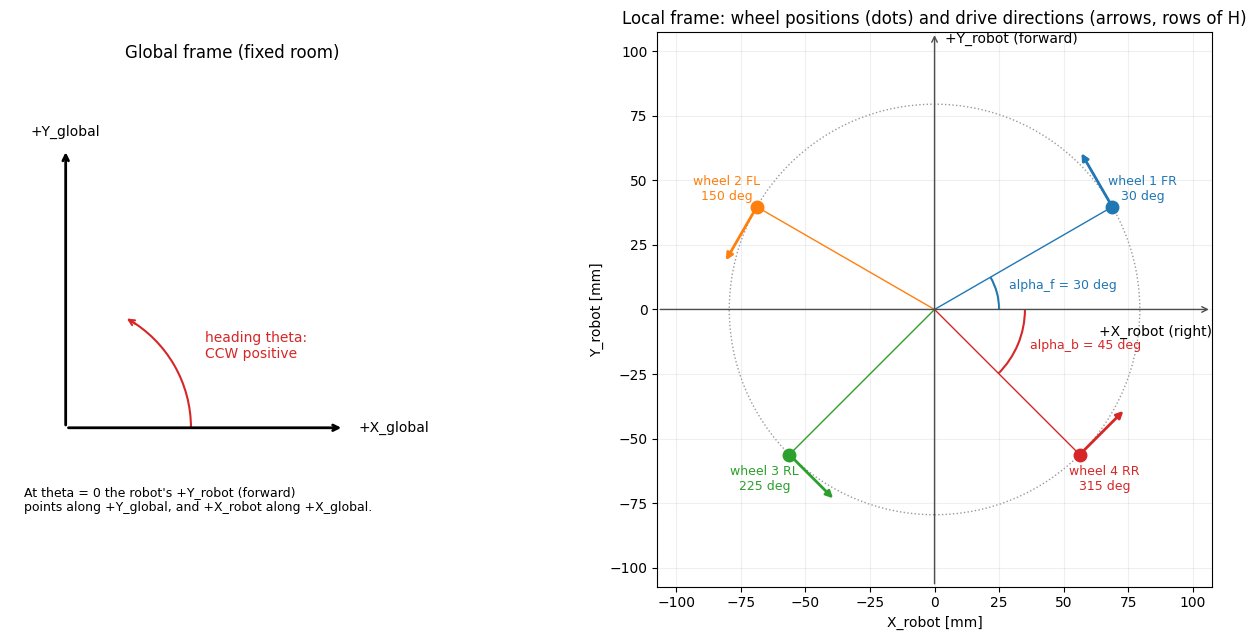

In [3]:
# Spatial reference frames and wheel layout, drawn from the model's own parameters (equal axes, so the angles are true)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc


def draw_layout(params):
    plant = OmniRobotSimulation(dict(params, sigma_V=0.0, sigma_mu=0.0))
    af, ab, Rb = params['alpha_f'], params['alpha_b'], params['Rb']
    beta = np.array([af, np.pi - af, np.pi + ab, 2.0 * np.pi - ab])       # wheel angles, CCW from +X_robot
    xy = Rb * 1e3 * np.column_stack((np.cos(beta), np.sin(beta)))         # wheel positions (mm)
    drive = plant.H[:, :2]                                               # drive direction of each wheel (rows of H)
    fig, (ax_g, ax) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 2]})

    # Global frame: X right, Y up; heading theta positive CCW
    ax_g.annotate("", xy=(1.0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax_g.annotate("", xy=(0, 1.0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
    ax_g.text(1.05, 0, "+X_global", va="center"); ax_g.text(0, 1.05, "+Y_global", ha="center")
    ax_g.add_patch(Arc((0, 0), 0.9, 0.9, theta1=0, theta2=60, color="C3", lw=1.5))
    ax_g.annotate("", xy=(0.45 * np.cos(np.radians(62)), 0.45 * np.sin(np.radians(62))),
                  xytext=(0.45 * np.cos(np.radians(55)), 0.45 * np.sin(np.radians(55))),
                  arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
    ax_g.text(0.5, 0.25, "heading theta:\nCCW positive", color="C3")
    ax_g.text(-0.15, -0.3, "At theta = 0 the robot's +Y_robot (forward)\npoints along +Y_global, and +X_robot along +X_global.", fontsize=9)
    ax_g.set(xlim=(-0.2, 1.4), ylim=(-0.45, 1.3), title="Global frame (fixed room)")
    ax_g.set_aspect("equal"); ax_g.axis("off")

    # Local frame: wheel positions and drive directions
    lim = 1.35 * Rb * 1e3
    ax.add_patch(plt.Circle((0, 0), Rb * 1e3, fill=False, ls=":", color="0.6"))
    ax.annotate("", xy=(lim, 0), xytext=(-lim, 0), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.annotate("", xy=(0, lim), xytext=(0, -lim), arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.text(lim, -6, "+X_robot (right)", ha="right", va="top"); ax.text(4, lim, "+Y_robot (forward)", va="top")
    names = ("1 FR", "2 FL", "3 RL", "4 RR")
    for i in range(4):
        px, py = xy[i]
        ax.plot([0, px], [0, py], color=f"C{i}", lw=1)
        ax.plot(px, py, "o", color=f"C{i}", ms=9)
        ax.annotate("", xy=(px + 25 * drive[i, 0], py + 25 * drive[i, 1]), xytext=(px, py),
                    arrowprops=dict(arrowstyle="-|>", color=f"C{i}", lw=2))
        ax.text(px * 1.17, py * 1.17, f"wheel {names[i]}\n{np.degrees(beta[i]) % 360:.0f} deg", ha="center", va="center",
                color=f"C{i}", fontsize=9)
    # alpha_f and alpha_b, measured from the +X_robot axis
    afd, abd = np.degrees(af), np.degrees(ab)
    ax.add_patch(Arc((0, 0), 50, 50, theta1=0, theta2=afd, color="C0", lw=1.5))
    ax.text(30 * np.cos(np.radians(afd / 2)), 30 * np.sin(np.radians(afd / 2)), f"alpha_f = {afd:.0f} deg", color="C0", fontsize=9)
    ax.add_patch(Arc((0, 0), 70, 70, theta1=-abd, theta2=0, color="C3", lw=1.5))
    ax.text(40 * np.cos(np.radians(-abd / 2)), 40 * np.sin(np.radians(-abd / 2)), f"alpha_b = {abd:.0f} deg", color="C3", fontsize=9)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel="X_robot [mm]", ylabel="Y_robot [mm]",
           title="Local frame: wheel positions (dots) and drive directions (arrows, rows of H)")
    ax.set_aspect("equal"); ax.grid(True, alpha=0.2)
    plt.tight_layout(); plt.show()


draw_layout(simulation_parameters)

# 🧪 Kinematic & Dynamic Verification Testing

This section executes open-loop verification trials to validate the electromechanical motor re-coupling, asymmetric kinematics mapping ($\mathbf{H}$), and stick-slip friction boundaries under hardware-verified sign directions.

### 📐 Structural Testing Grid Architecture
The execution pipeline performs a **multi-block comparative analysis** across two distinct physical frame designs and environmental settings:
1. **Block 1: Symmetric Frame Verification:** Configures the plant layout to an identical 45° alignment across all wheel lines ($\alpha_f = 45^\circ$, $\alpha_b = 45^\circ$).
2. **Block 2: Asymmetric Frame Verification:** Reverts the plant setup back to your custom asymmetric layout ($\alpha_f = 30^\circ$, $\alpha_b = 45^\circ$).

### 🕹️ Verification Test Input Sequences
To isolate each independent degree of freedom, the simulation applies precise step voltage patterns across the four wheel motors:
*   **Test 1: Forward Motion ($\mathbf{V} = [2.0, -2.0, -2.0, 2.0]^\top$):** Applies positive voltages to the right-side motors ($1, 4$) and negative voltages to the left-side motors ($2, 3$). This drives all wheels to push the ground backward symmetrically, canceling out lateral side forces and accelerating the robot straight ahead along its local $+Y_r$ axis.
*   **Test 2: Lateral Side-Strafing ($\mathbf{V} = [-2.0, -2.0, 2.0, 2.0]^\top$):** Applies negative voltages to the front axle motors ($1, 2$) and positive voltages to the rear axle motors ($3, 4$). This mirrors the longitudinal forces across the front-to-back split line, causing forward and backward vectors to cancel out. The remaining lateral components combine to push the chassis cleanly sideways to the right along its local $+X_r$ axis.
*   **Test 3: Pure Rotational Spinning ($\mathbf{V} = [2.0, 2.0, 2.0, 2.0]^\top$):** Applies uniform positive voltages to all four wheels simultaneously. Because every omni-wheel is mounted tangentially to the chassis base circle, spinning them all in the same rotational direction eliminates all linear translation vectors and creates a pure angular torque, spinning the robot counter-clockwise ($+\theta$) around its Center of Mass.

### 🔄 Dual-Pass State Conditions
To clearly isolate the degradation caused by environmental disturbances, each vehicle geometry executes a sequential dual-pass simulation:
*   **Ideal Pass (Reference Baseline):** Strips all noise configurations ($\sigma_V = 0.0$, $\sigma_\mu = 0.0$). The results render as soft, transparent curves representing perfect theoretical trajectories.
*   **Perturbed Pass (Real-World Overlay):** Activates a repeatable, seeded random number generator stream (`np.random.default_rng`) to overlay high-frequency structural chassis vibrations ($w_F$) and spatial friction coefficient patches ($w_\mu$).

### 📊 Logged Telemetry Variables
Each configuration runs the three directional maneuvers back-to-back over a 1.5-second time window (1500 discrete calculation steps) and generates a standalone 2x2 grid capturing:
*   **Applied Motor Terminal Voltages ($V_{1\dots4}$):** Verifies step-input directional polarities.
*   **Wheel Angular Velocities ($\omega_{1\dots4}$):** Monitors electromechanical back-EMF variations and independent rotor spinout integrations ($J_w$).
*   **Chassis Local Frame Speeds ($\dot{x}_r, \dot{y}_r, \dot{\theta}$):** Evaluates translational and angular momentum unbalances inside the mass matrix universe ($\mathbf{M}^{-1}\mathbf{H}^\top\mathbf{F}_k$).
*   **Global Position Tracking ($X-Y$ Trajectory Plane):** Visualizes dead-reckoning coordinate transformation drift paths directly overlaying ideal performance vs. noisy tracking realities.

Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...


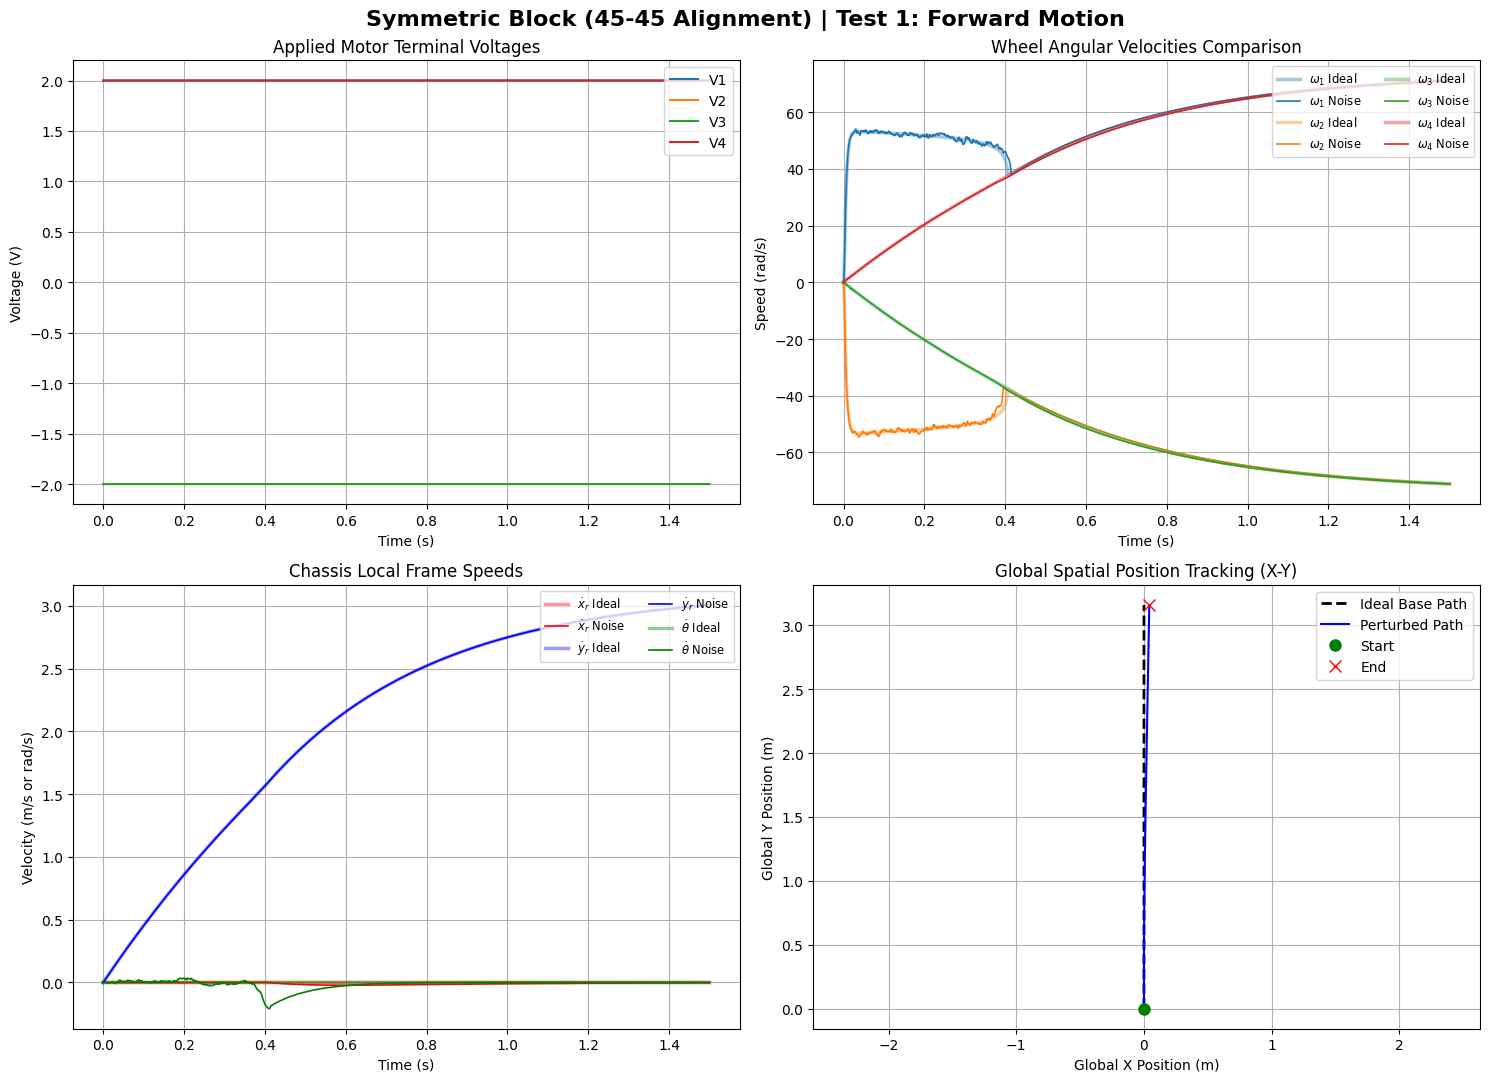

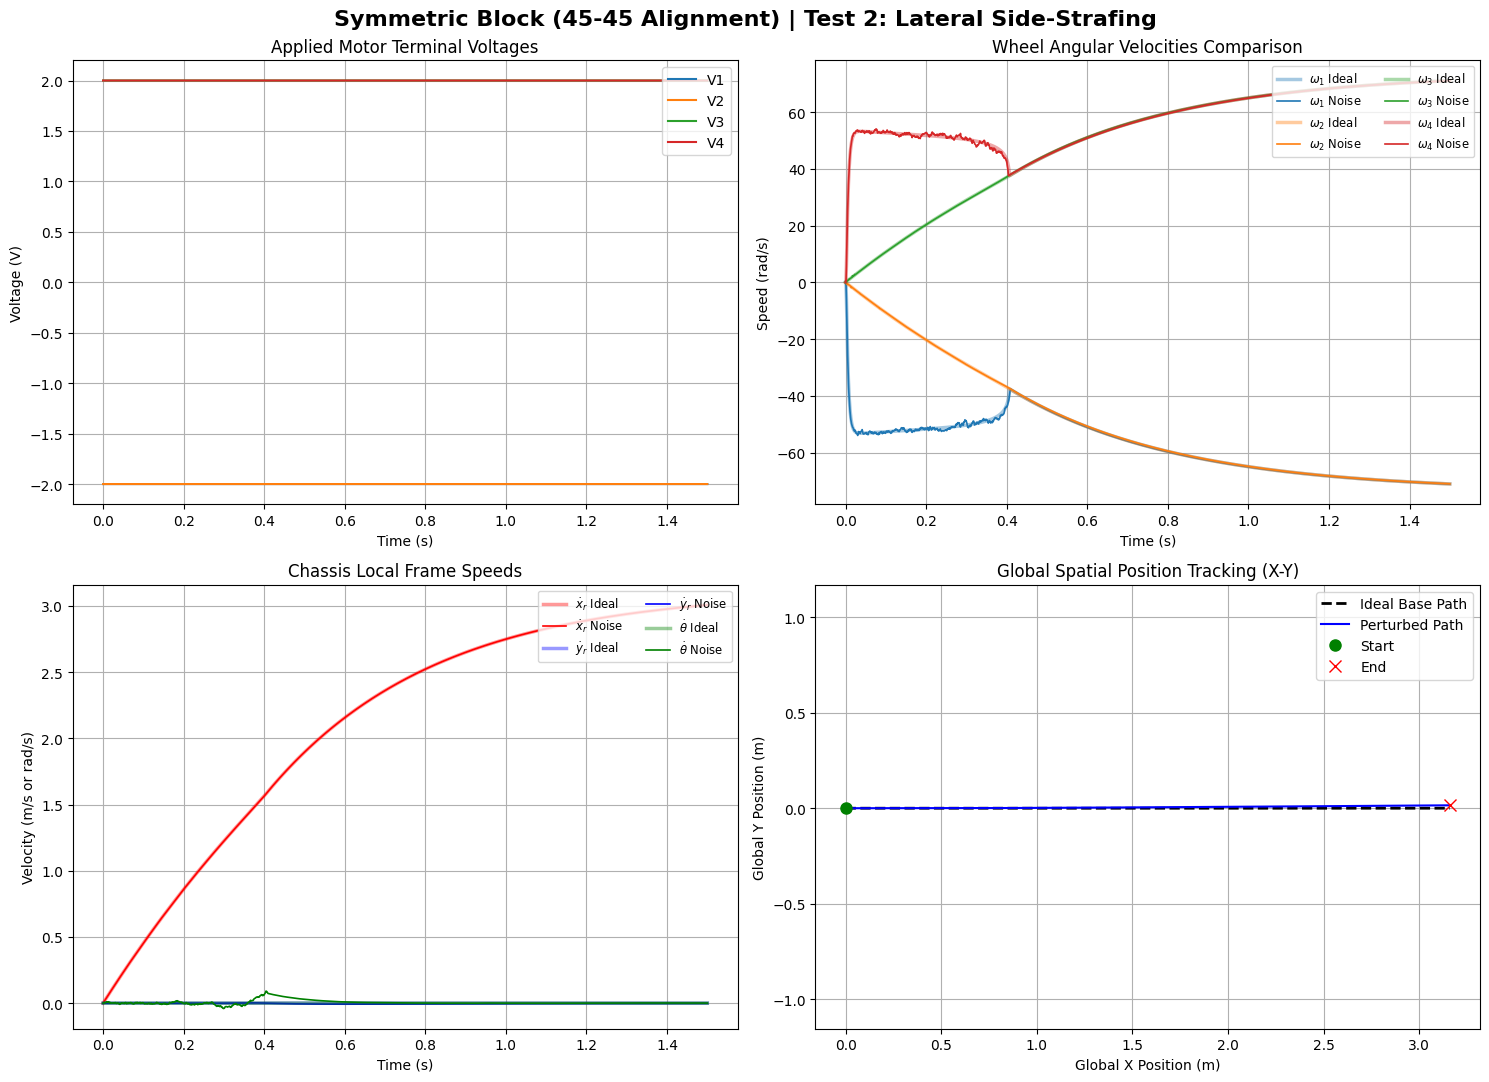

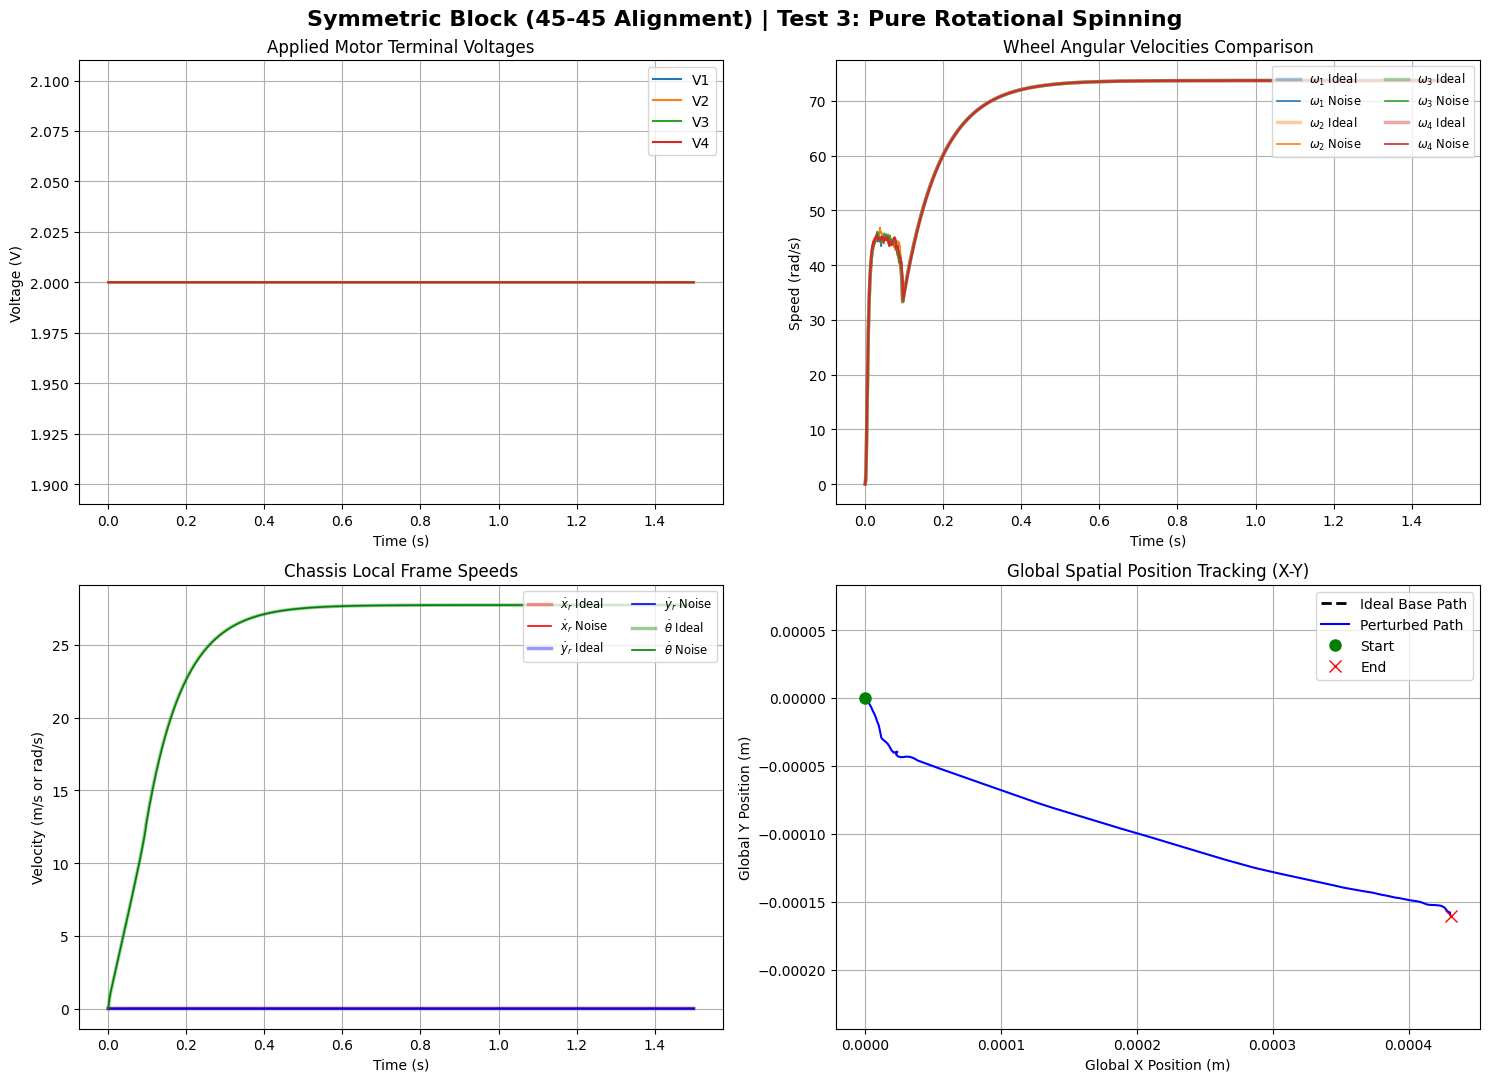

In [4]:
import numpy as np
import matplotlib.pyplot as plt

nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

t_end = 1.5  
dt = simulation_parameters['dt']
steps = int(t_end / dt)
t_vec = np.linspace(0, t_end, steps)

low_voltage = 2
maneuvers = [
    {"name": "Test 1: Forward Motion", "V": np.array([low_voltage, -low_voltage, -low_voltage, low_voltage])},
    {"name": "Test 2: Lateral Side-Strafing", "V": np.array([-low_voltage, -low_voltage, low_voltage, low_voltage])},
    {"name": "Test 3: Pure Rotational Spinning", "V": np.array([low_voltage, low_voltage, low_voltage, low_voltage])}
]

# REMOVED redundancy: line style 'ls' is isolated out of the style modifiers
style_ideal = {'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'alpha': 1.0, 'lw': 1.2}  

# CONFIGURATION CHANGE: FORCE SYMMETRIC 45-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(45.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 1: Symmetric 45-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, V_cmd=m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Symmetric Block (45-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Isolated style configuration)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...


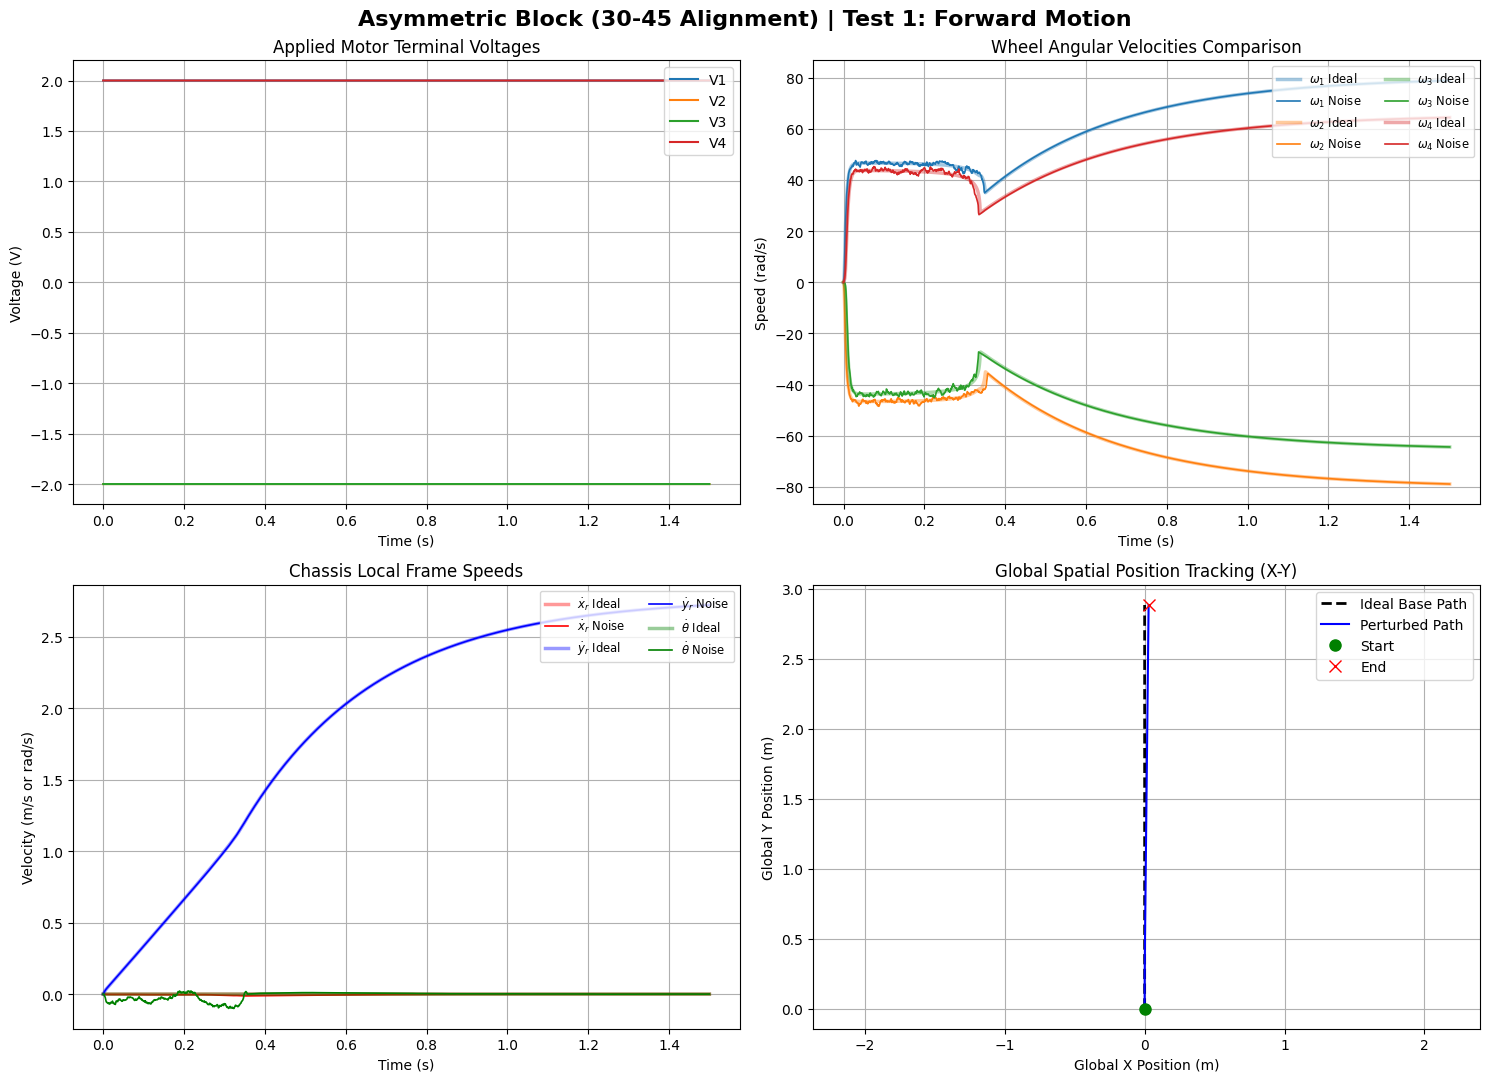

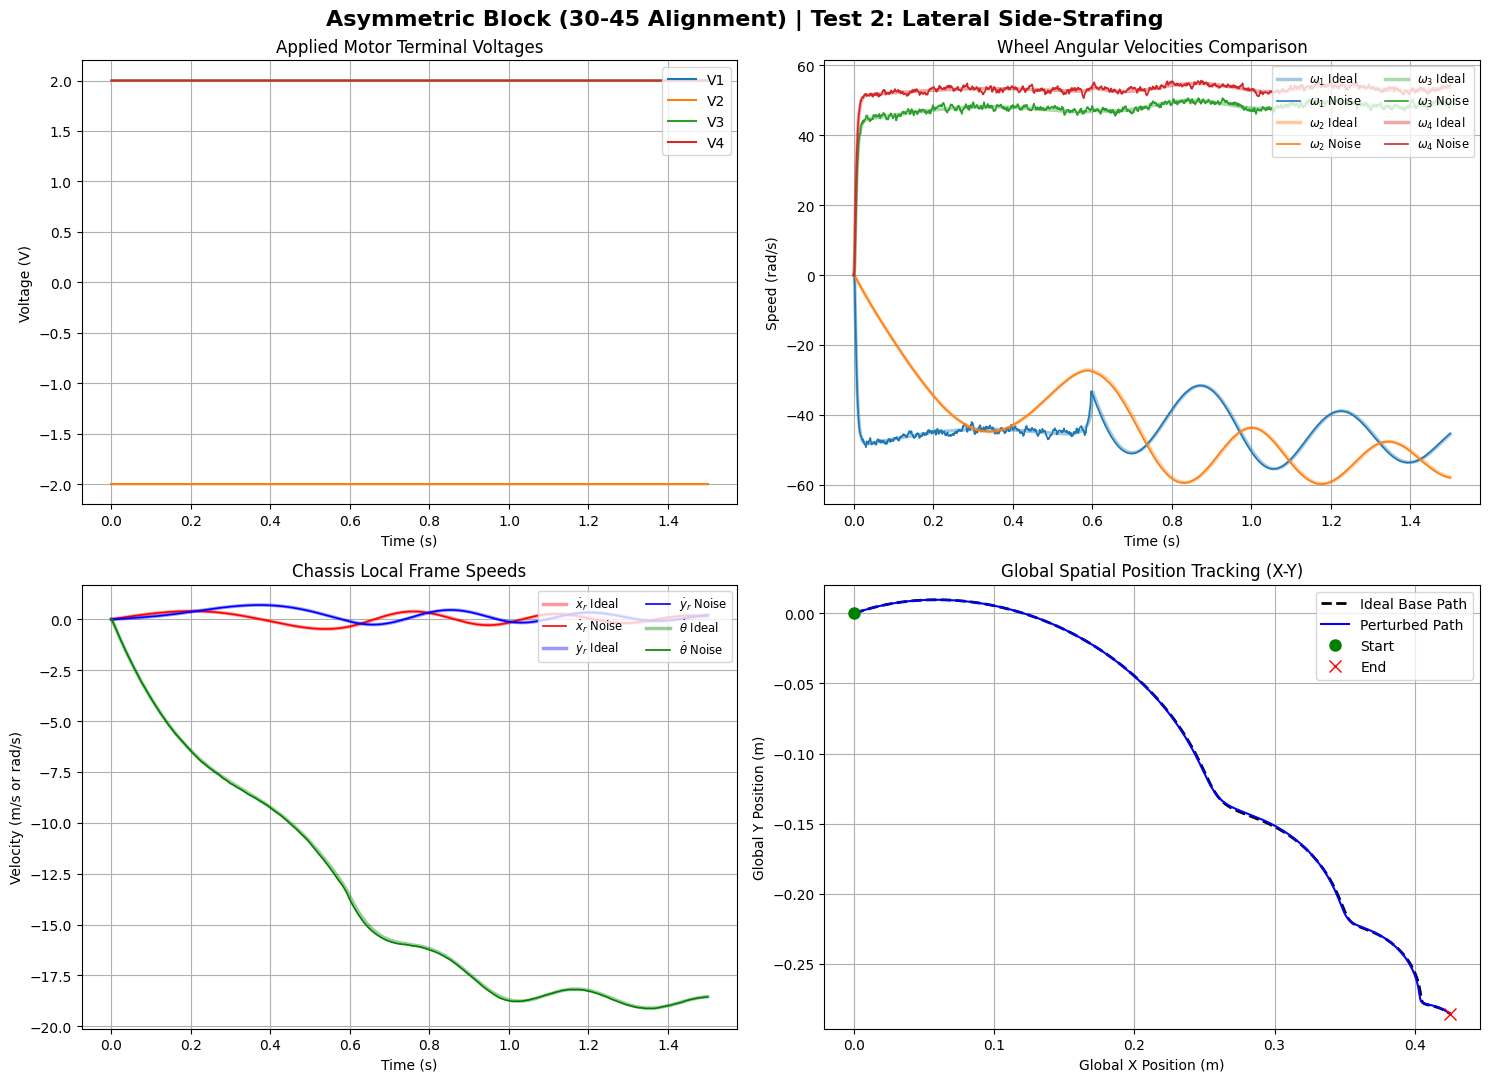

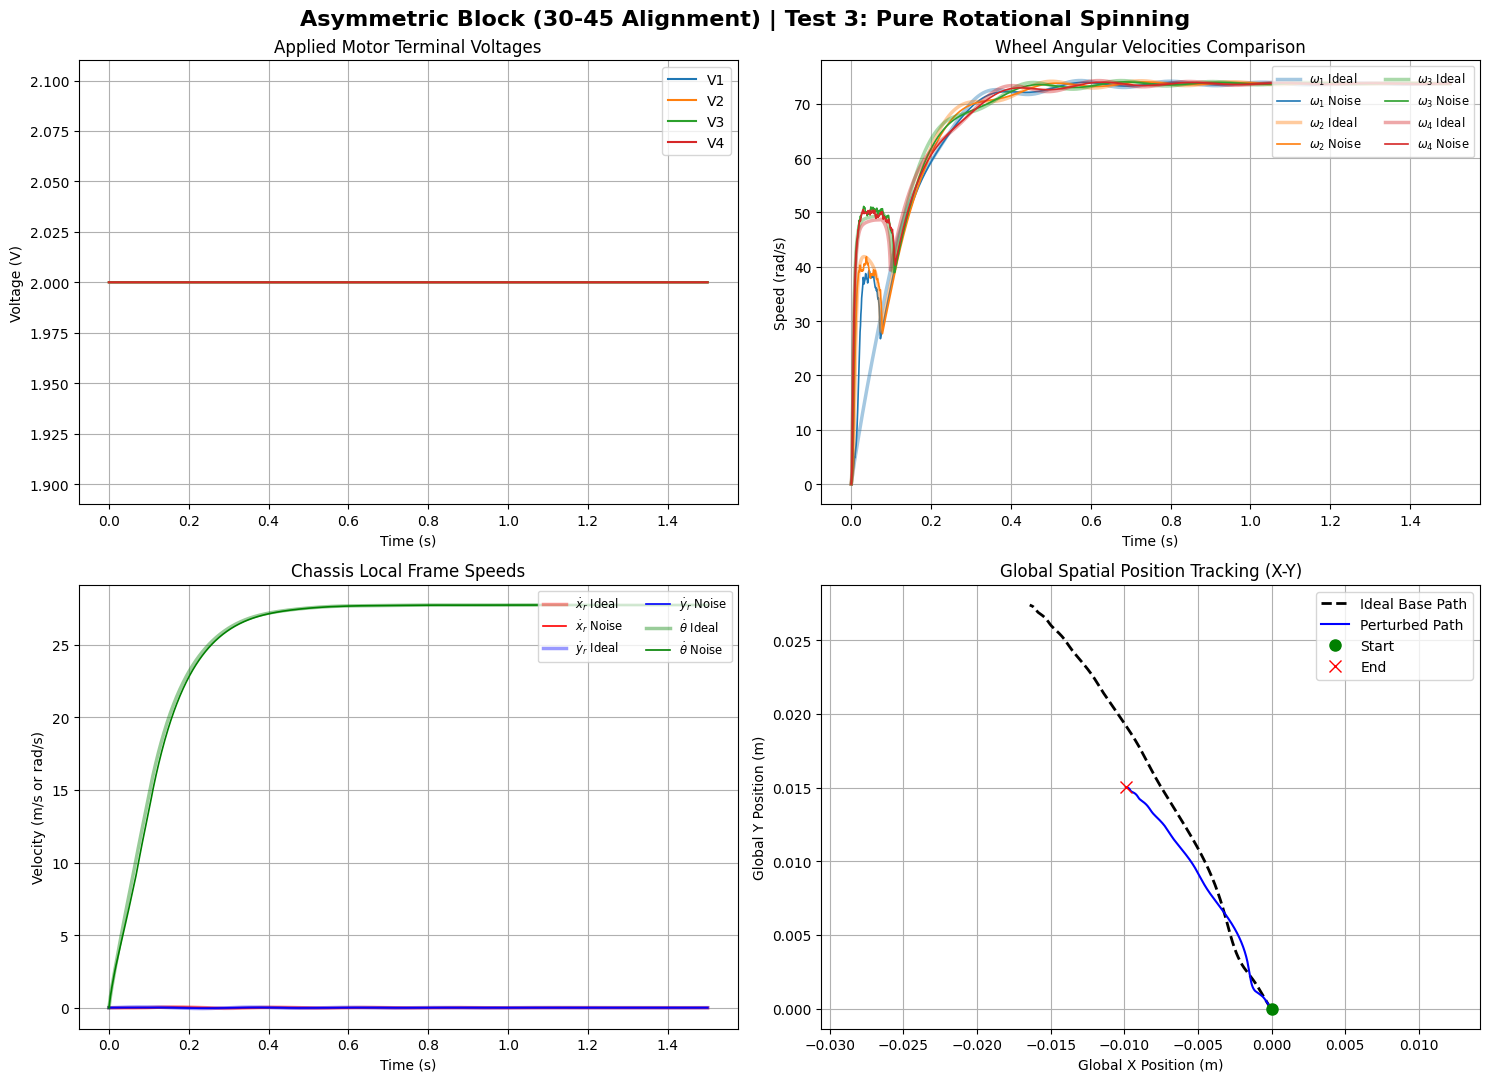

In [5]:
# CONFIGURATION CHANGE: REVERT TO ASYMMETRIC 30-45 DESIGN
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Block 2: Asymmetric 30-45 Wheel Angle Configurations...")

for m in maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, V_cmd=m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Block (30-45 Alignment) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds (FIXED: Raw string notation used)
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities (FIXED: Line parameters isolated)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Safely restore baseline parameter noise variables back to configuration dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu

Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...


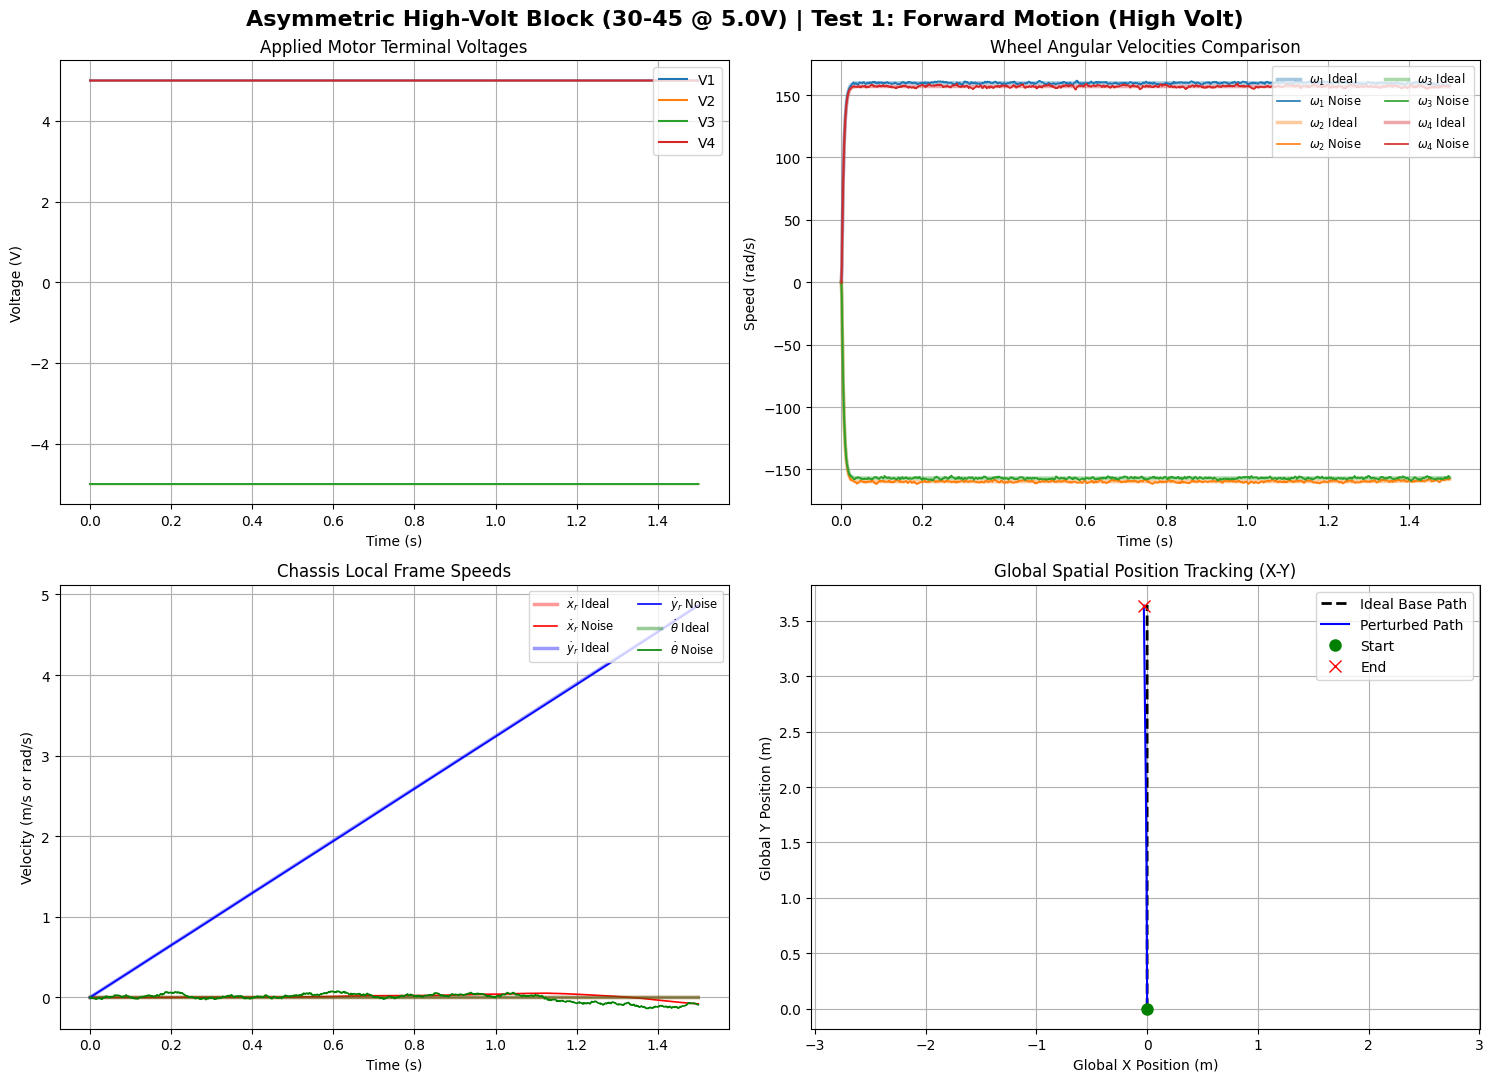

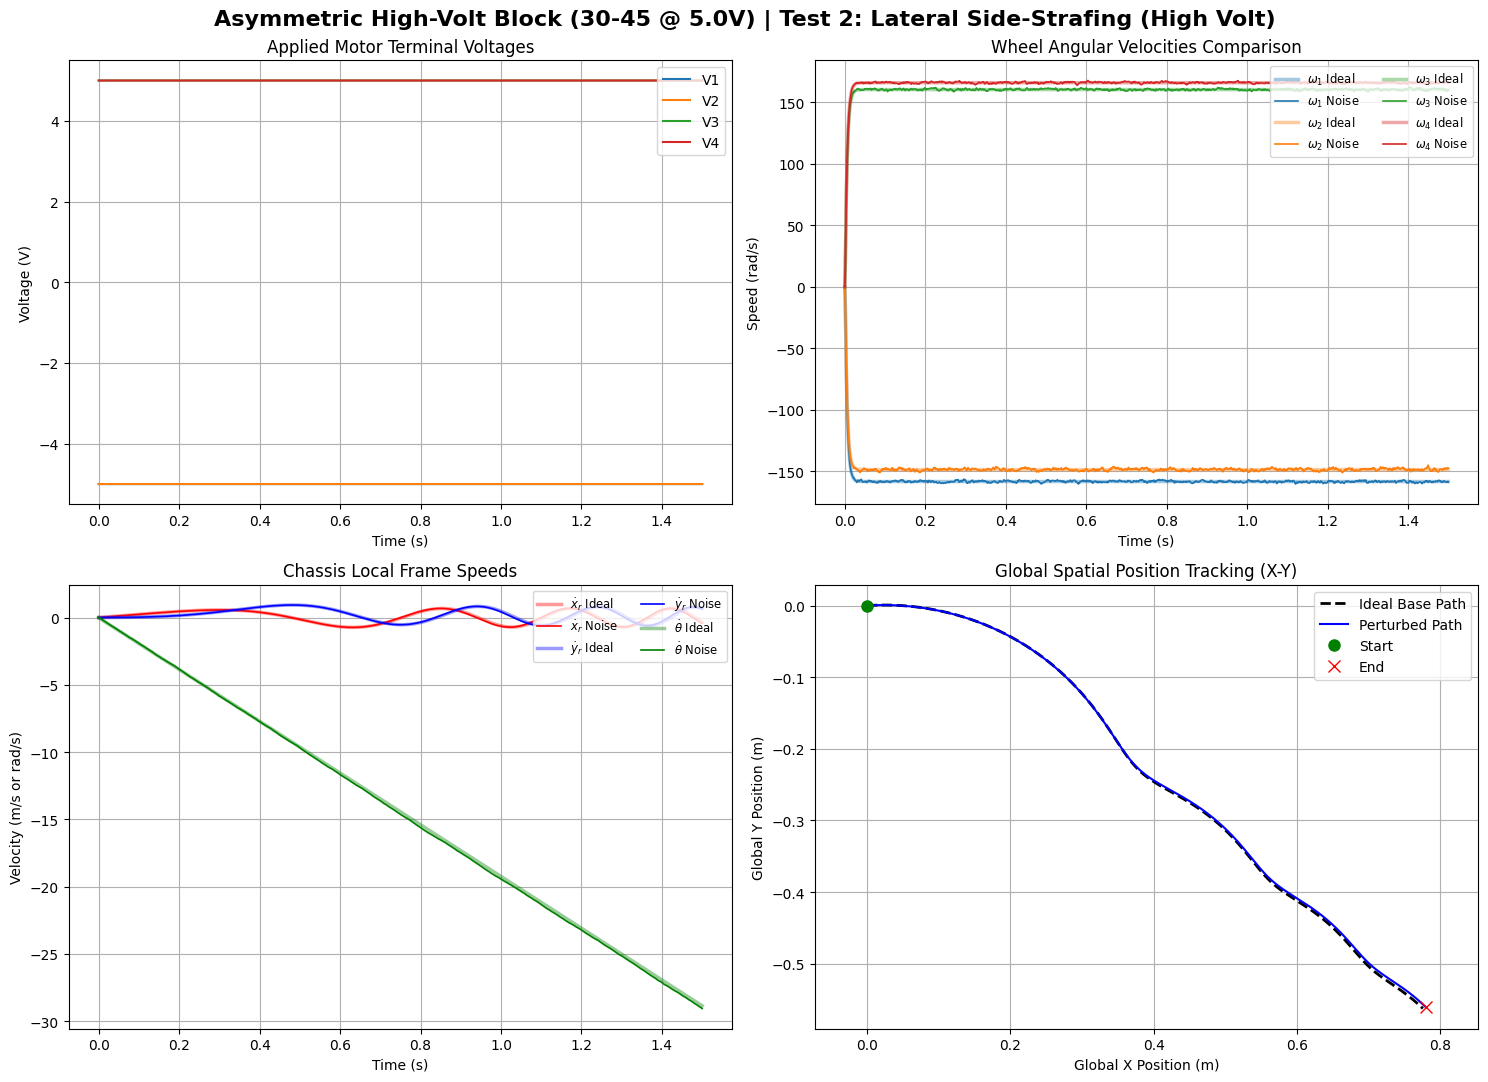

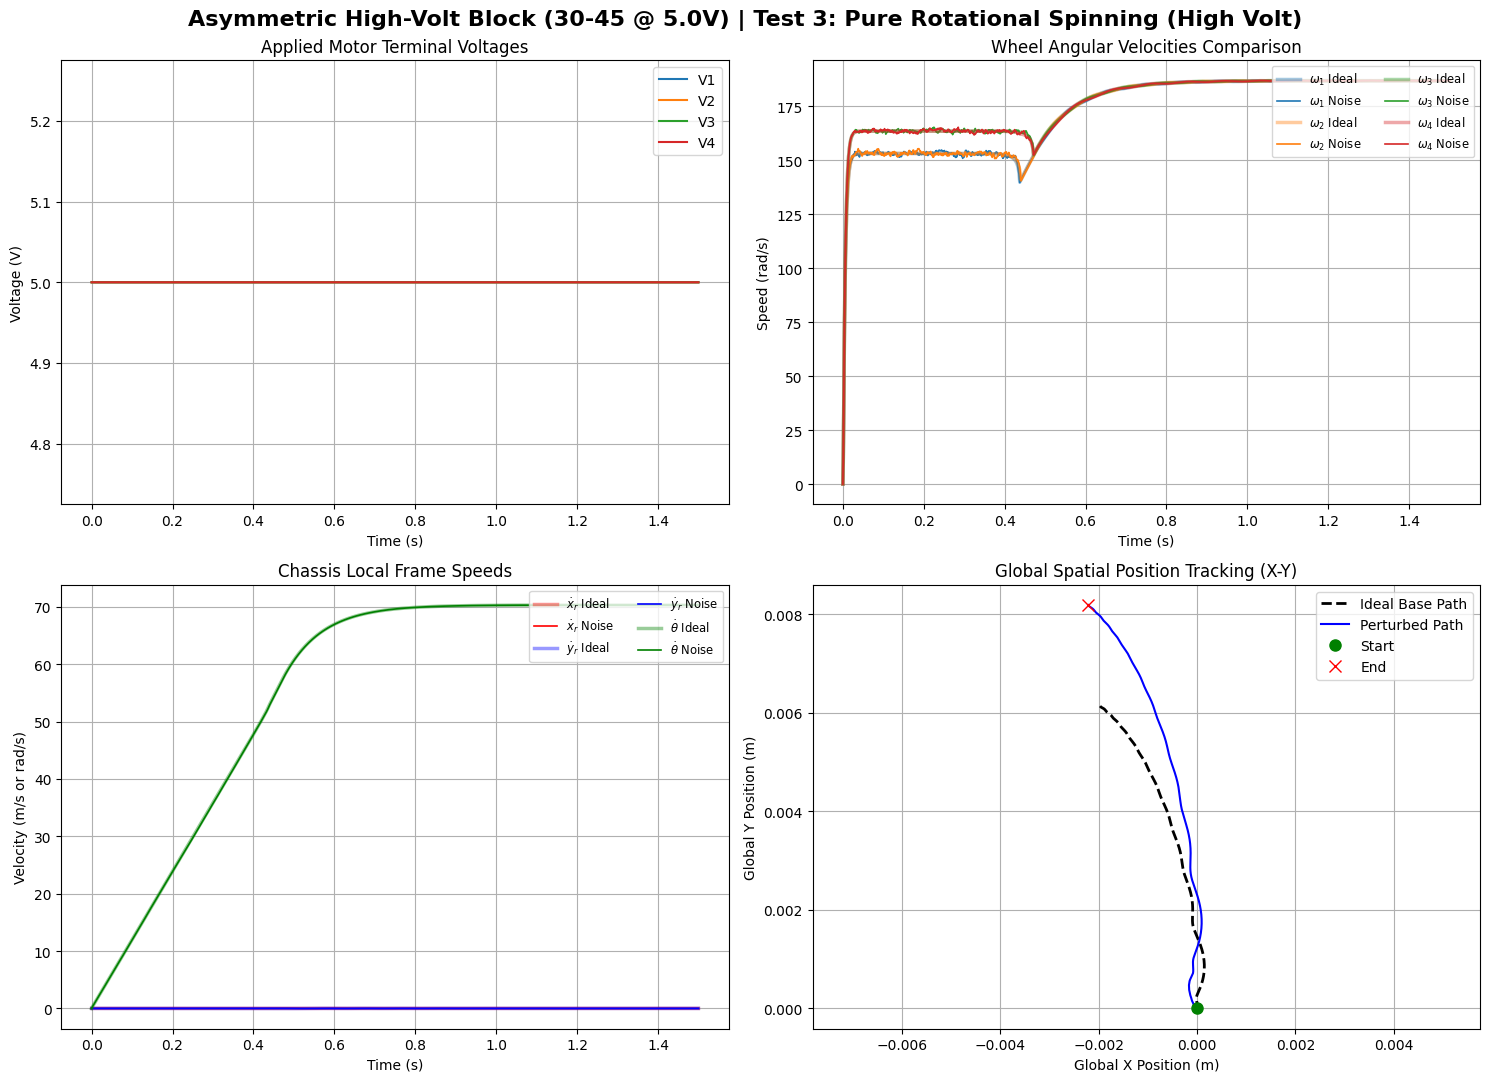

In [6]:
# =======================================================================
# CONFIGURATION CHANGE: KEEP ASYMMETRIC 30-45 DESIGN BUT BOOST TO 5.0V
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

bost_voltage = 5.0

# Define high-voltage directional maneuvers matching your verified sign choices
high_volt_maneuvers = [
    {"name": "Test 1: Forward Motion (High Volt)", "V": np.array([bost_voltage, -bost_voltage, -bost_voltage, bost_voltage])},
    {"name": "Test 2: Lateral Side-Strafing (High Volt)", "V": np.array([-bost_voltage, -bost_voltage, bost_voltage, bost_voltage])},
    {"name": "Test 3: Pure Rotational Spinning (High Volt)", "V": np.array([bost_voltage, bost_voltage, bost_voltage, bost_voltage])}
]

print("Executing Block 3: Asymmetric 30-45 Wheel Angle Configurations at High Voltage (5.0V)...")

for m in high_volt_maneuvers:
    runs_data = {}
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        # Instantiate plant under custom asymmetric high-volt conditions (Seeded for reproducibility)
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        for k in range(steps):
            v_in_hist.append(m["V"].copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            state, T_load, S_status = robot_plant.step(state, V_cmd=m["V"])
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric High-Volt Block (30-45 @ 5.0V) | {m['name']}", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Inputs
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Terminal Voltages"); axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], '-', color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities Comparison"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Chassis Velocities
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Speeds"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Spatial Position Tracking (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Final safe restoration of baseline parameter noise variables back to dictionary
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu

# 🧪 Multi-Stage Sequence Verification Testing

This section updates the verification routines to implement a **Multi-Stage Step Profile Timeline**. Instead of using simple, constant voltage step inputs, each directional test commands a dynamic voltage profile divided into three sequential 1.0-second stages. This structure explicitly evaluates your plant's transient response, high-velocity deceleration behavior, and rolling drag coasting decays.

### 🕹️ Chronological Stage Sequences
For each of the three directional axes, the simulation pushes a dynamic voltage vector $\mathbf{U}_k$ that varies depending on the current time step interval:
1.  **Stage 1: Positive Command Interval ($0.0\text{s} \le t < 1.0\text{s}$):** Motors receive a $+4.0$V scaled step command based on your hardware sign choices to accelerate the robot from a dead stop.
2.  **Stage 2: Negative/Reversal Interval ($1.0\text{s} \le t < 2.0\text{s}$):** Voltages instantly flip polarity to $-4.0$V. This forces the motor drives to act as active plug-brakes, fighting the massive momentum of the chassis, decelerating it to a stop, and reversing its trajectory.
3.  **Stage 3: Zero/Coasting Interval ($2.0\text{s} \le t \le 3.0\text{s}$):** Voltage commands drop flat to $0.0$V. The robot's electrical drive cuts out entirely, forcing the vehicle to coast to a complete stop purely by bleeding kinetic energy through the wheels' internal parasitic rolling resistance ($C_{rr}$).

### 🗺️ Multi-Stage Directional Key
The three tests map these positive/negative/zero step magnitudes to the following hardware-verified wheel groups:
*   **Test 1: Forward/Backward Sequence:** Drives straight ahead along local $+Y_r$, plugs the motors into reverse to fly backward along $-Y_r$, and then cuts voltage to zero.
*   **Test 2: Side-to-Side Sequence:** Strafes directly left along local $-X_r$, reverses direction to strafe back right along $+X_r$, and then drops into a dead coast.
*   **Test 3: CCW/CW Rotation Sequence:** Spins the entire robot counter-clockwise ($+\theta$) around its Center of Mass, actively reverses momentum into a clockwise spin ($-\theta$), and then coasts down.

### 🔄 Comparative Telemetry Observations
By stringing these phases back-to-back, the generated 2x2 graphics grids highlight critical non-linear coupling effects across the **Ideal vs. Disturbed** runs:
*   **Transient Speed Chattering:** At the $t = 1.0$s mark, when the voltage violently snaps from positive to negative, the wheels experience a massive sudden torque unbalance while the vehicle chassis is still moving forward. This breaks floor adhesion and causes **prolonged, high-frequency wheel speed spikes** on the disturbed plots as wheels lose grip and spin out independently.
*   **Deceleration and Coasting Curves:** Subplot 3 visualizes the real-world back-EMF damping slopes during reverse braking, alongside the long exponential velocity decay during the final unpowered coasting interval.
*   **Trajectory Drift Accumulation:** Subplot 4 maps the absolute spatial motion. It marks exactly where the direction switches happen (`Switch to Neg` and `Switch to Zero`), illustrating how uneven wheel spinouts during violent direction changes heavily amplify open-loop navigation drift away from the baseline ideal path.

Executing Profile Tests under Asymmetric 30-45 Geometry...


C:\Users\Henry\AppData\Local\Temp\ipykernel_23096\21193898.py:106: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
C:\Users\Henry\AppData\Local\Temp\ipykernel_23096\21193898.py:107: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "r-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
C:\Users\Henry\AppData\Local\Temp\ipykernel_23096\21193898.py:108: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
C

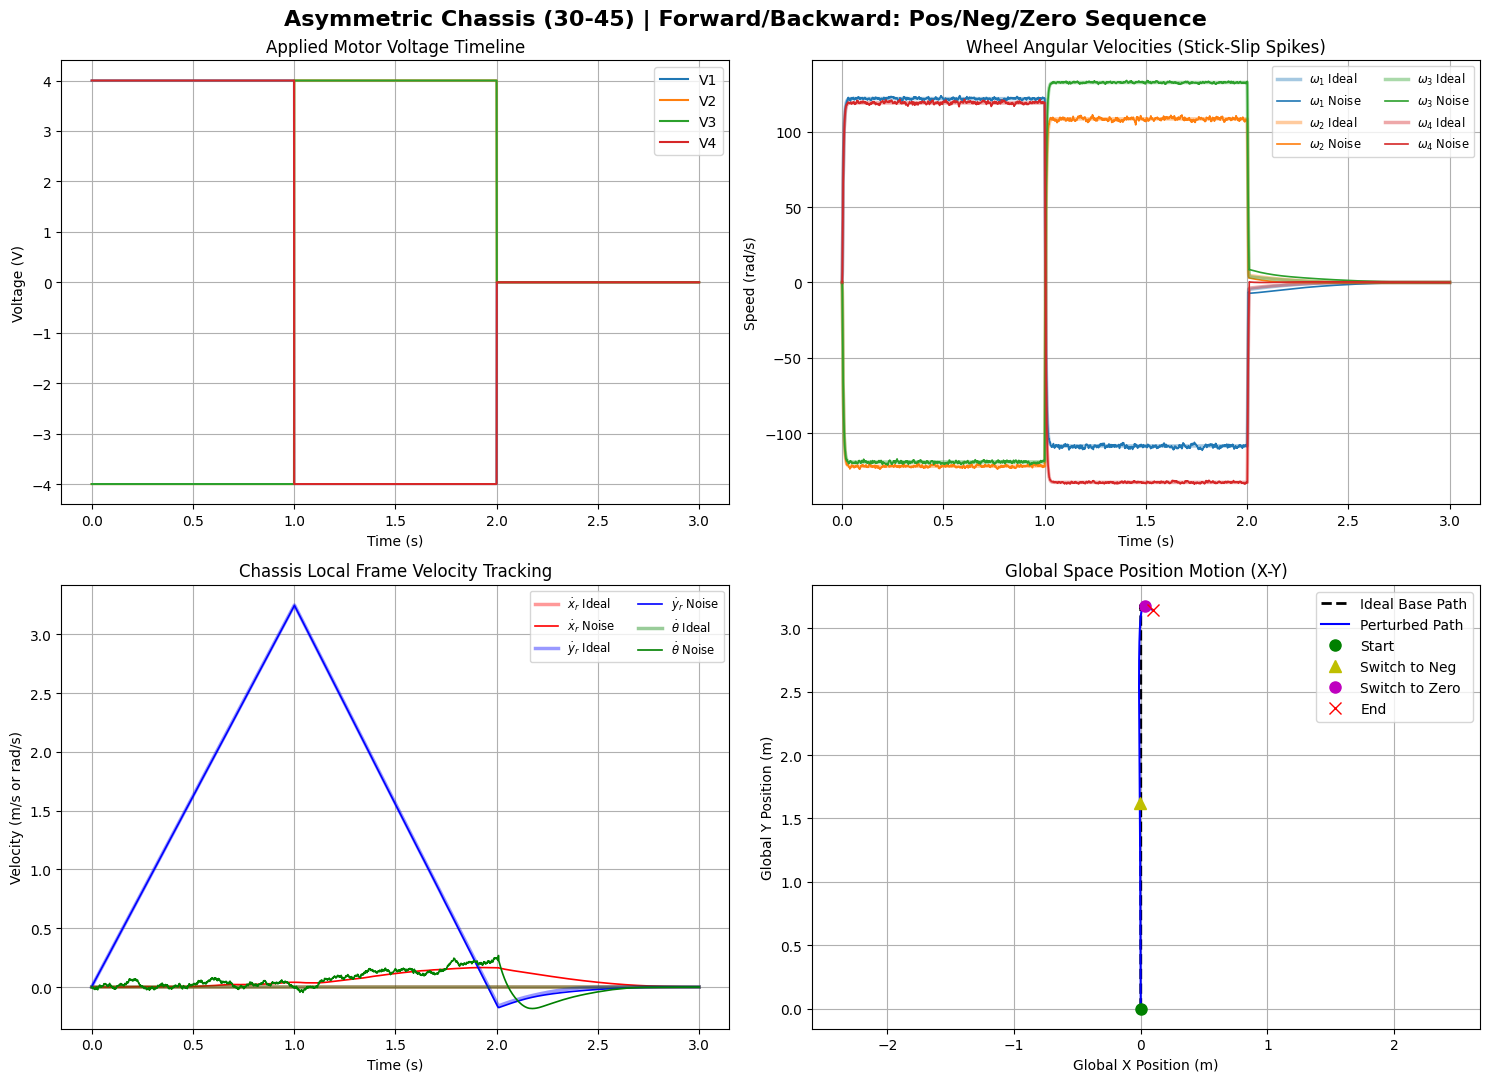

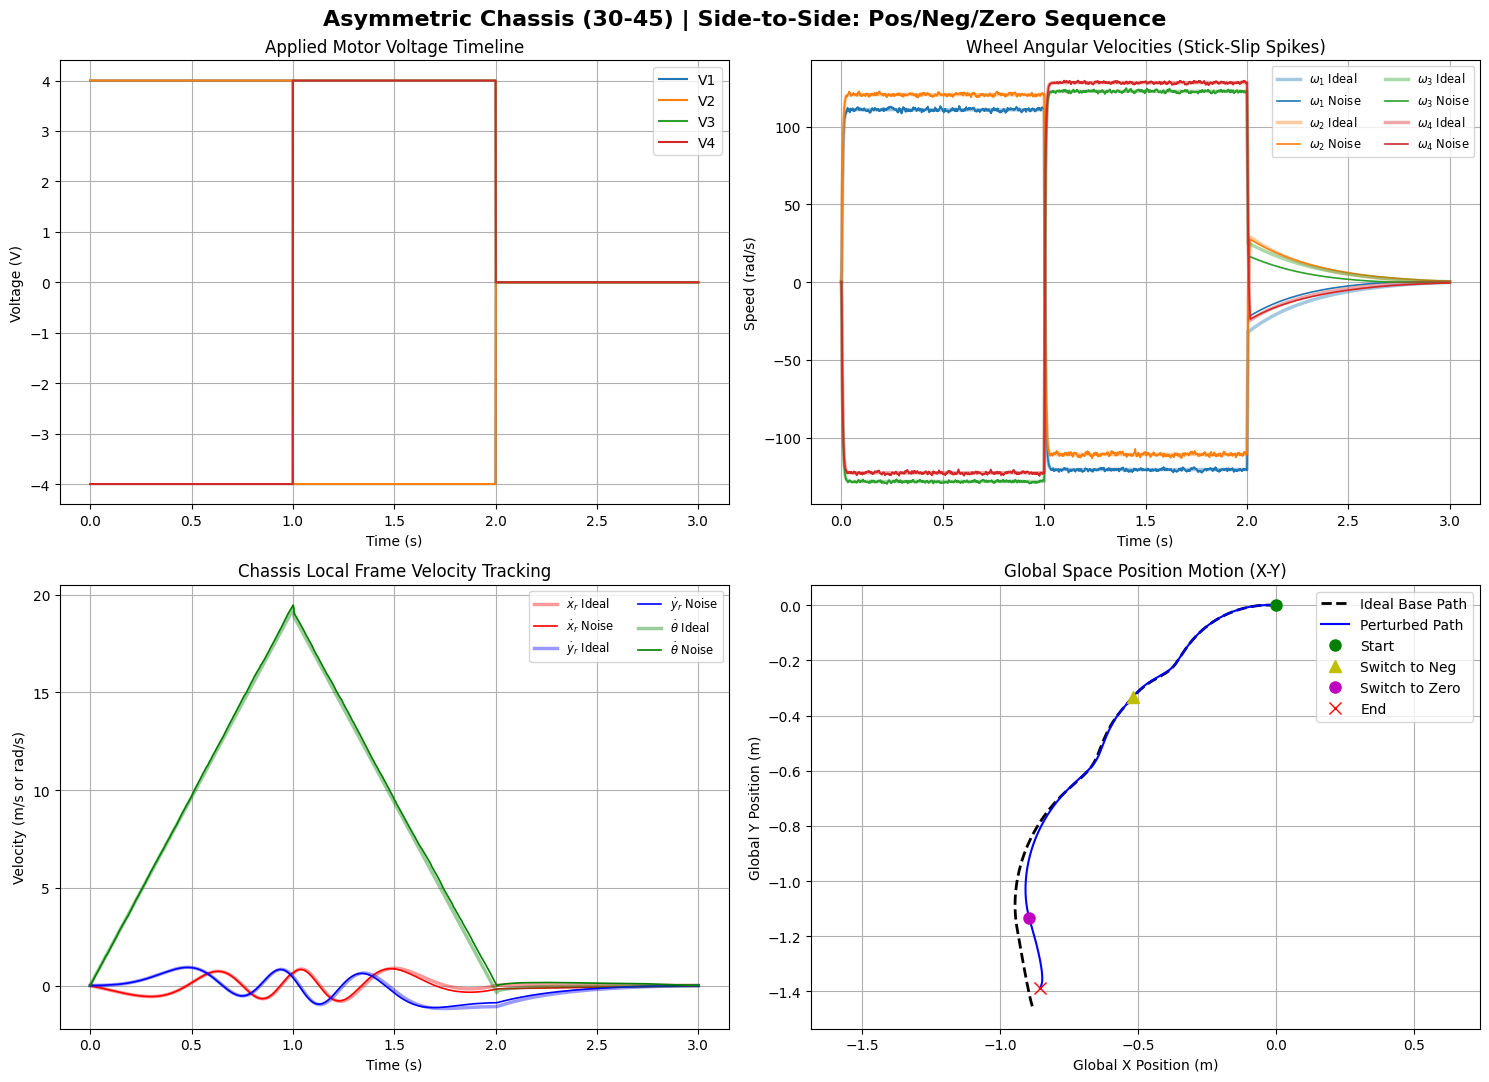

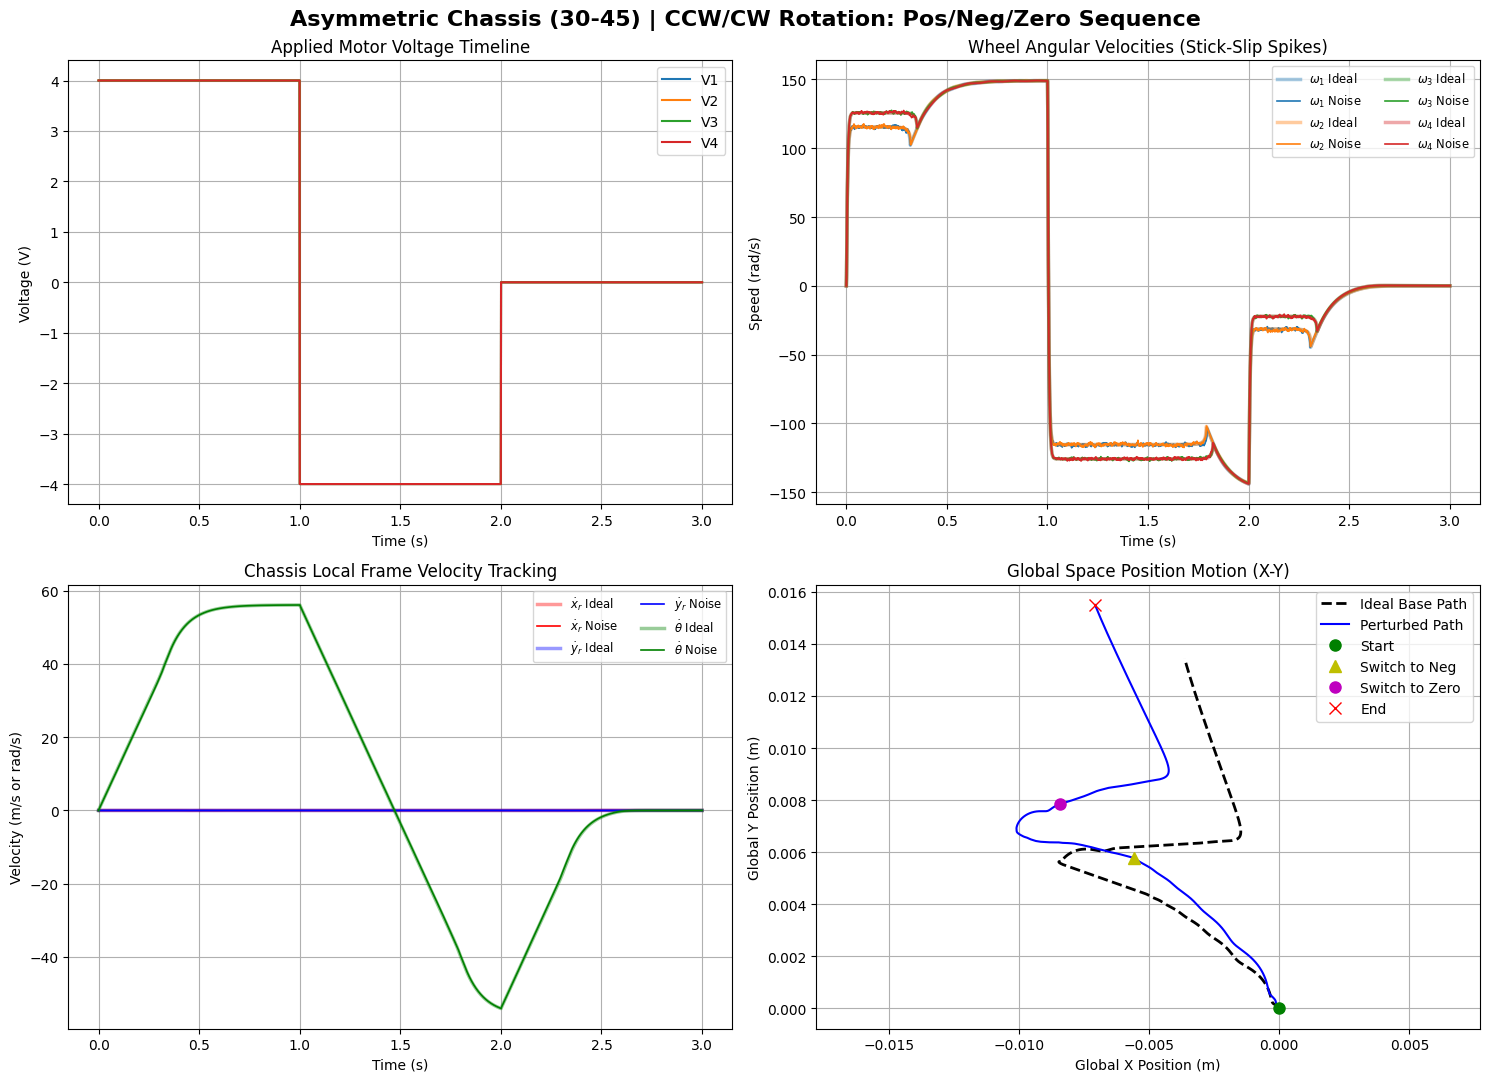

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Save your configured noise parameters to toggle the passes cleanly
nominal_sigma_V = simulation_parameters['sigma_V']
nominal_sigma_mu = simulation_parameters['sigma_mu']

# Define a 3.0 second timeline split into three distinct 1.0s intervals
t_stage = 1.0
dt = simulation_parameters['dt']
steps_per_stage = int(t_stage / dt)
total_steps = steps_per_stage * 3
t_vec = np.linspace(0, t_stage * 3, total_steps)

# Helper function to dynamically generate the voltage vector at any given step index k
def get_profile_voltage(test_type, step_idx, steps_per_stage):
    # Determine which chronological stage we are currently executing
    if step_idx < steps_per_stage:
        stage = "Positive"
        mag = 4.0
    elif step_idx < 2 * steps_per_stage:
        stage = "Negative"
        mag = -4.0
    else:
        stage = "Zero"
        mag = 0.0
        
    # Apply your verified hardware directional sign combinations scaled by stage magnitude
    if test_type == "Forward/Backward":
        return np.array([mag, -mag, -mag, mag])
    elif test_type == "Side-to-Side":
        return np.array([mag, mag, -mag, -mag])
    elif test_type == "CCW/CW Rotation":
        return np.array([mag, mag, mag, mag])
    return np.zeros(4)

# Define our three complex multi-stage test scenarios
test_scenarios = ["Forward/Backward", "Side-to-Side", "CCW/CW Rotation"]

# Plotting configuration styles
style_ideal = {'ls': '-', 'alpha': 0.4, 'lw': 2.5}  
style_noisy = {'ls': '-', 'alpha': 1.0, 'lw': 1.2}  

# =======================================================================
# STRUCTURAL RUN 1: ASYMMETRIC 30-45 CONFIGURATION WITH PROFILE MANEUVERS
# =======================================================================
simulation_parameters['alpha_f'] = np.radians(30.0)
simulation_parameters['alpha_b'] = np.radians(45.0)

print("Executing Profile Tests under Asymmetric 30-45 Geometry...")

for test_name in test_scenarios:
    runs_data = {}
    
    for condition in ["Ideal", "With Disturbances"]:
        if condition == "Ideal":
            simulation_parameters['sigma_V'] = 0.0
            simulation_parameters['sigma_mu'] = 0.0
        else:
            simulation_parameters['sigma_V'] = nominal_sigma_V
            simulation_parameters['sigma_mu'] = nominal_sigma_mu
            
        robot_plant = OmniRobotSimulation(simulation_parameters, random_seed=42)
        state = OmniMotorState()
        
        v_in_hist, omega_hist, v_local_hist, pos_global_hist = [], [], [], []
        
        # Step through the full 3.0 second timeline
        for k in range(total_steps):
            V_cmd = get_profile_voltage(test_name, k, steps_per_stage)
            
            v_in_hist.append(V_cmd.copy())
            omega_hist.append(state.omega.copy())
            v_local_hist.append(state.v_local.copy())
            pos_global_hist.append(state.pos_global.copy())
            
            state, T_load, S_status = robot_plant.step(state, V_cmd=V_cmd)
            
        runs_data[condition] = {
            "V": np.array(v_in_hist), "omega": np.array(omega_hist),
            "v_local": np.array(v_local_hist), "pos_global": np.array(pos_global_hist)
        }
        
    ideal = runs_data["Ideal"]
    noisy = runs_data["With Disturbances"]

    # -------------------------------------------------------------------
    # GENERATE 2x2 GRAPHS FOR COMPLEX PROFILE COUPLING
    # -------------------------------------------------------------------
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    fig.suptitle(f"Asymmetric Chassis (30-45) | {test_name}: Pos/Neg/Zero Sequence", fontsize=16, fontweight='bold')
    
    # Subplot 1: Voltage Profiles (Now showing step changes over time)
    for w in range(4): 
        axs[0, 0].plot(t_vec, ideal["V"][:, w], label=f'V{w+1}')
    axs[0, 0].set_title("Applied Motor Voltage Timeline")
    axs[0, 0].set_xlabel("Time (s)"); axs[0, 0].set_ylabel("Voltage (V)"); axs[0, 0].grid(True); axs[0, 0].legend(loc="upper right")
    
    # Subplot 2: Wheel Speeds showing spikes during aggressive direction switches
    for w in range(4):
        axs[0, 1].plot(t_vec, ideal["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Ideal', **style_ideal)
        axs[0, 1].plot(t_vec, noisy["omega"][:, w], color=f'C{w}', label=r'$\omega_{' + str(w+1) + r'}$ Noise', **style_noisy)
    axs[0, 1].set_title("Wheel Angular Velocities (Stick-Slip Spikes)"); axs[0, 1].set_xlabel("Time (s)"); axs[0, 1].set_ylabel("Speed (rad/s)"); axs[0, 1].grid(True); axs[0, 1].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 3: Local Frame Velocities showing Braking/Deceleration Curves
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 0], 'r-', label=r'$\dot{x}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 1], 'b-', label=r'$\dot{y}_r$ Noise', **style_noisy)
    axs[1, 0].plot(t_vec, ideal["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Ideal', **style_ideal)
    axs[1, 0].plot(t_vec, noisy["v_local"][:, 2], 'g-', label=r'$\dot{\theta}$ Noise', **style_noisy)
    axs[1, 0].set_title("Chassis Local Frame Velocity Tracking"); axs[1, 0].set_xlabel("Time (s)"); axs[1, 0].set_ylabel("Velocity (m/s or rad/s)"); axs[1, 0].grid(True); axs[1, 0].legend(loc="upper right", ncol=2, fontsize='small')
    
    # Subplot 4: Global Trajectory Plane showing bidirectional path trace
    axs[1, 1].plot(ideal["pos_global"][:, 0], ideal["pos_global"][:, 1], 'k--', lw=2.0, label='Ideal Base Path')
    axs[1, 1].plot(noisy["pos_global"][:, 0], noisy["pos_global"][:, 1], 'b-', lw=1.5, label='Perturbed Path')
    axs[1, 1].plot(noisy["pos_global"][0, 0], noisy["pos_global"][0, 1], 'go', markersize=8, label='Start')
    axs[1, 1].plot(noisy["pos_global"][steps_per_stage, 0], noisy["pos_global"][steps_per_stage, 1], 'y^', markersize=8, label='Switch to Neg')
    axs[1, 1].plot(noisy["pos_global"][2*steps_per_stage, 0], noisy["pos_global"][2*steps_per_stage, 1], 'mo', markersize=8, label='Switch to Zero')
    axs[1, 1].plot(noisy["pos_global"][-1, 0], noisy["pos_global"][-1, 1], 'rx', markersize=8, label='End')
    axs[1, 1].set_title("Global Space Position Motion (X-Y)"); axs[1, 1].set_xlabel("Global X Position (m)"); axs[1, 1].set_ylabel("Global Y Position (m)"); axs[1, 1].set_aspect('equal', 'datalim'); axs[1, 1].grid(True); axs[1, 1].legend(loc="best")
    
    plt.tight_layout()
    plt.show()

# Restore baseline parameters securely
simulation_parameters['sigma_V'] = nominal_sigma_V
simulation_parameters['sigma_mu'] = nominal_sigma_mu